In [2]:
import pandas as pd
import ast

# charging data process
charging_sessions = pd.read_csv(
    "Data Share/charging_sessions.csv",
    index_col=0,
    dtype={"userID": str, "siteID": str}
)

# Remove identical records; check conflicting session IDs separately.
charging_sessions = charging_sessions.drop_duplicates().reset_index(drop=True)
charging_sessions["siteID"] = pd.to_numeric(charging_sessions["siteID"]).astype("Int64")

# userInputs
user_inputs = charging_sessions["userInputs"].fillna("[]").apply(
    ast.literal_eval
).apply(lambda x: x[0] if x else {})
user_inputs = pd.DataFrame(
    user_inputs.tolist(), index=charging_sessions.index
).add_prefix("input_")
charging_sessions = charging_sessions.join(user_inputs)

# Keep raw userInputs for later analysis of revised requests.
for column in ["connectionTime", "disconnectTime", "doneChargingTime",
               "input_modifiedAt", "input_requestedDeparture"]:
    charging_sessions[column] = pd.to_datetime(
        charging_sessions[column], utc=True, errors="coerce"
    ).dt.tz_convert("America/Los_Angeles")

# Calculate Durations
# Connected Duration
charging_sessions["connected_duration_hours"] = (charging_sessions["disconnectTime"] - charging_sessions["connectionTime"]).dt.total_seconds() / 3600
# Charging Duration
charging_sessions["charging_duration_hours"] = (charging_sessions["doneChargingTime"] - charging_sessions["connectionTime"]).dt.total_seconds() / 3600

# anomalous records
# anomalous1: connectionTime" or "disconnectTime“ is missing
charging_sessions["invalid_connection_time"] = (
    charging_sessions[["connectionTime", "disconnectTime"]].isna().any(axis=1)
    | charging_sessions["connected_duration_hours"].lt(0)
)
# anomalous2: doneChargingTime is missing
charging_sessions["missing_done_time"] = charging_sessions["doneChargingTime"].isna()
# anomalous3: doneChargingTime is earlier than connectionTime or later than disconnectTime
charging_sessions["invalid_done_time"] = (
    charging_sessions["doneChargingTime"].lt(charging_sessions["connectionTime"])
    | charging_sessions["doneChargingTime"].gt(charging_sessions["disconnectTime"])
)

# fillna with anomalous
charging_sessions.loc[charging_sessions["invalid_connection_time"], "connected_duration_hours"] = float("nan")
charging_sessions.loc[charging_sessions["invalid_connection_time"] | charging_sessions["invalid_done_time"], "charging_duration_hours"] = float("nan")


def column_summary(frame):
    """Summarize data types and missing values for every column."""
    return pd.DataFrame({
        "Data type": frame.dtypes.astype(str),
        "Missing values": frame.isna().sum(),
        "Missing (%)": (frame.isna().mean() * 100).round(2),
    }).rename_axis("Column")

# weather
weather = pd.read_csv('Data Share/weather_burbank_airport.csv')
weather["timestamp"] = pd.to_datetime(weather["timestamp"])


**Data-quality finding.**   
Deduplication leaves 65,037 sessions: 33,629 at site 1 and 31,408 at site 2.  
Session identifiers are unique. Approximately 13.07% of connection-to-last-current durations are unavailable after validation.   
Connection times, disconnection times and delivered energy support the main analysis;   
charging-completion-based measures have weaker coverage. Weather is not used in the models because its timezone and coverage require separate alignment.

### Feature Engineering

| Dimension | Session Features | User Aggregation |
|---|---|---|
| Temporal Preference | Arrival hour, weekday | Circular mean, weekend share |
| Charging Demand | Energy delivered | Mean, SD |
| Parking Behavior | Connected duration | Mean, SD |
| Charging Behavior | Time until charging completed | Mean, SD |
| Flexibility Proxy | Post-charge idle duration, idle ratio | Mean, median |
| Regularity | Arrival time, inter-session gap | Circular dispersion, gap variability |
| Charging Frequency | Session date | Sessions per active week |


#

| Feature	| Clustering	| Adaptation |
|---|---|---|
| Arrival sin/cos	| ✓	| ✓ | 
| Weekend share	| ✓	| ✓ | 
| Mean energy	| ✓	| ✓ | 
| Mean connected hours	| ✓	| ✓ | 
| Mean charging hours	| optional	| ✓ | 
| Mean idle ratio	| opyional	| ✓ | 
| Charging frequency	| ✓	| ✓ | 
| Behavioral variability	| opyional	| ✓ | 

 **1. User Clustering — Between-user Heterogeneity**
Identify different types of EV charging behavior across users.

Data Structure:
- One row per user.
- Features include behavioral means, variability, frequency, and regularity.
- K-means / Gaussian Mixture Models (GMM) / HDBSCAN

**2. Behavioral Adaptation — Within-user Adaptation**
Analyze how individual users' charging behavior changes over time.

Data Structure:
- One row per user per month.
- Use consistent behavioral features across time periods.

Research Questions:
1. Does user charging behavior become more stable over time?
2. Do users change their preferred charging times?
3. Do users transition between different behavioral clusters?
4. How are behavioral changes associated with time, seasonality, or other observable factors?

In [4]:
import numpy as np
# Feature Engineering
df = charging_sessions.loc[~charging_sessions["invalid_connection_time"]& charging_sessions["kWhDelivered"].gt(0)].copy()

# Session-level Features
# Temporal features
df["date"] = df["connectionTime"].dt.tz_localize(None)
df["month"] = df["date"].dt.to_period("M")
df["quarter"] = df["date"].dt.to_period("Q")
df["arrival_hour"] = df["date"].dt.hour + df["date"].dt.minute / 60
df["departure_hour"] = (df["disconnectTime"].dt.hour+ df["disconnectTime"].dt.minute / 60)
df["arrival_weekday"] = df["date"].dt.dayofweek
df["is_weekend"] = df["arrival_weekday"].ge(5).astype(int)
# Cyclical temporal features
df["arrival_sin"] = np.sin(2 * np.pi * df["arrival_hour"] / 24)
df["arrival_cos"] = np.cos(2 * np.pi * df["arrival_hour"] / 24)
df["month_sin"] = np.sin(2 * np.pi * df["date"].dt.month / 12)
df["month_cos"] = np.cos(2 * np.pi * df["date"].dt.month / 12)
# Duration features
df["connected_hours"] = df["connected_duration_hours"]
df["charging_hours"] = df["charging_duration_hours"]
df["idle_hours"] = (df["connected_hours"] - df["charging_hours"]).clip(lower=0)
df["idle_ratio"] = (df["idle_hours"] / df["connected_hours"].replace(0, np.nan))
# Energy features
df["energy_kWh"] = df["kWhDelivered"]
df["avg_power_kW"] = (df["energy_kWh"] / df["charging_hours"].replace(0, np.nan))
# Regularity fatures
df = df.sort_values(["siteID", "userID", "connectionTime"])
df["inter_session_days"] = (df.groupby(["siteID", "userID"])["connectionTime"].diff().dt.total_seconds() / 86400)

# User-level Features — Clustering
user_features = (
    df.dropna(subset=["userID"])
    .groupby(["siteID", "userID"])
    .agg(
        # Frequency
        session_count=("sessionID", "size"),
        # Temporal preference
        arrival_sin=("arrival_sin", "mean"),
        arrival_cos=("arrival_cos", "mean"),
        weekend_share=("is_weekend", "mean"),
        # Charging demand
        mean_energy_kWh=("energy_kWh", "mean"),
        sd_energy_kWh=("energy_kWh", "std"),
        # Parking behavior
        mean_connected_hours=("connected_hours", "mean"),
        sd_connected_hours=("connected_hours", "std"),
        # Charging behavior
        mean_charging_hours=("charging_hours", "mean"),
        sd_charging_hours=("charging_hours", "std"),
        # Flexibility proxy
        mean_idle_hours=("idle_hours", "mean"),
        median_idle_hours=("idle_hours", "median"),
        mean_idle_ratio=("idle_ratio", "mean"),
        # Regularity
        mean_inter_session_days=("inter_session_days", "mean"),
        sd_inter_session_days=("inter_session_days", "std"),
        # Observation period
        first_session=("date", "min"),
        last_session=("date", "max")
    )
    .reset_index()
)

# Frequency over observed time span
user_features["observation_months"] = ((user_features["last_session"] - user_features["first_session"]).dt.total_seconds() / (86400 * 30.4375))
user_features["sessions_per_month"] = (user_features["session_count"] / user_features["observation_months"].clip(lower=1))


# User-month Features — Behavioral Adaptation
user_month_features = (
    df.dropna(subset=["userID"])
    .groupby(["siteID", "userID", "month"])
    .agg(
        # Frequency
        session_count=("sessionID", "size"),

        # Temporal preference
        arrival_sin=("arrival_sin", "mean"),
        arrival_cos=("arrival_cos", "mean"),
        weekend_share=("is_weekend", "mean"),

        # Charging demand
        mean_energy_kWh=("energy_kWh", "mean"),
        sd_energy_kWh=("energy_kWh", "std"),

        # Parking behavior
        mean_connected_hours=("connected_hours", "mean"),
        sd_connected_hours=("connected_hours", "std"),

        # Charging behavior
        mean_charging_hours=("charging_hours", "mean"),
        sd_charging_hours=("charging_hours", "std"),

        # Flexibility proxy
        mean_idle_hours=("idle_hours", "mean"),
        median_idle_hours=("idle_hours", "median"),
        mean_idle_ratio=("idle_ratio", "mean"),

        # Regularity
        mean_inter_session_days=("inter_session_days", "mean"),
        sd_inter_session_days=("inter_session_days", "std")
    )
    .reset_index()
)

user_month_features["sessions_per_month"] = (user_month_features["session_count"])

## Research setup

RQ1: What session types occur independently at each site? Identified-user clustering at site 1 provides a complementary user-level view.

RQ2: How do session-type proportions and within-type characteristics change over time at each site? Site 1 additionally supports matched-user analysis.

RQ3: How well do descriptive patterns and arrival-time prediction models transfer between sites?

The common reference period is September 2018–June 2019. July–September 2019 is used for user-stability diagnostics, and October–December 2019 for held-out comparisons. RQ2 also describes the longer record, with gaps retained. Site 2 is treated as anonymous sessions throughout the main analysis.

In [5]:
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score, adjusted_rand_score


reference_start = pd.Timestamp("2018-09-01")
reference_end = pd.Timestamp("2019-07-01")
stability_end = pd.Timestamp("2019-10-01")
test_end = pd.Timestamp("2020-01-01")

users = df.loc[ df["siteID"].eq(1) & df["userID"].notna()].copy()

profile_features = [
    # Temporal preference
    "arrival_sin",
    "arrival_cos",
    "weekend_share",
    # Charging demand
    "mean_energy_kWh",
    "sd_energy_kWh",
    # Parking behavior
    "mean_connected_hours",
    "sd_connected_hours",
    # Charging behavior
    "mean_charging_hours",
    "sd_charging_hours",
    # Flexibility proxy
    "mean_idle_ratio",
    # Regularity
    "sd_inter_session_days",
    # Frequency
    "sessions_per_month"
]


def user_profiles(data, start, end, minimum=5):

    window = data.loc[data["date"].ge(start) & data["date"].lt(end) ].copy()
    window = window.sort_values(["userID", "date"])

    # Recalculate gaps within each time window
    window["inter_session_days"] = ( window.groupby("userID")["date"].diff().dt.total_seconds() / 86400)

    profile = window.groupby("userID").agg(
        session_count=("sessionID", "size"),
        arrival_sin=("arrival_sin", "mean"),
        arrival_cos=("arrival_cos", "mean"),
        weekend_share=("is_weekend", "mean"),
        mean_energy_kWh=("energy_kWh", "mean"),
        sd_energy_kWh=("energy_kWh", "std"),
        mean_connected_hours=("connected_hours", "mean"),
        sd_connected_hours=("connected_hours", "std"),
        mean_charging_hours=("charging_hours", "mean"),
        sd_charging_hours=("charging_hours", "std"),
        mean_idle_ratio=("idle_ratio", "mean"),
        sd_inter_session_days=("inter_session_days", "std")
    )
    # Fixed-window frequency
    profile["sessions_per_month"] = (profile["session_count"]  / ((end - start).days / 30.4375))

    return profile.loc[profile["session_count"].ge(minimum)].copy()

reference = user_profiles(users, reference_start, reference_end, minimum=10)
future = user_profiles( users, reference_end, stability_end, minimum=5)

print("Reference users:", len(reference))
print("Future users:", len(future))

if len(reference) < 3:
    raise ValueError("At least 3 reference users are required.")

if len(future) == 0:
    raise ValueError("No eligible users in the future period.")


# Missing values and standardization
# Remove features that are entirely missing in reference
selected_features = [col for col in profile_features if reference[col].notna().any()]
print("Selected features:", selected_features)

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X = scaler.fit_transform(imputer.fit_transform(reference[selected_features]))
future_X = scaler.transform(imputer.transform(future[selected_features]))
common = reference.index.intersection(future.index)
print("Matched users:", len(common))

Reference users: 196
Future users: 177
Selected features: ['arrival_sin', 'arrival_cos', 'weekend_share', 'mean_energy_kWh', 'sd_energy_kWh', 'mean_connected_hours', 'sd_connected_hours', 'mean_charging_hours', 'sd_charging_hours', 'mean_idle_ratio', 'sd_inter_session_days', 'sessions_per_month']
Matched users: 145


### RQ1 supplementary analysis — Identified users at site 1

Choose K using reference-period silhouettes only. Compare later profiles using both fixed reference centroids and independently refitted clusters. Labels describe charging behavior, not psychological traits. Frequency means visits recorded at this site, not total charging frequency.

   silhouette   inertia
k                      
2       0.219  1855.609
3       0.247  1456.701
4       0.212  1319.580
5       0.201  1215.173
6       0.189  1126.725
Best K: 3
Reference cluster profiles:
       arrival_sin  arrival_cos  weekend_share  mean_energy_kWh  \
group                                                             
0            0.681       -0.377          0.018           28.346   
1           -0.173       -0.638          0.027           12.321   
2            0.775       -0.305          0.016            9.155   

       sd_energy_kWh  mean_connected_hours  sd_connected_hours  \
group                                                            
0             11.005                 8.023               2.468   
1              5.238                 4.307               2.264   
2              2.302                 8.196               2.389   

       mean_charging_hours  sd_charging_hours  mean_idle_ratio  \
group                                                        

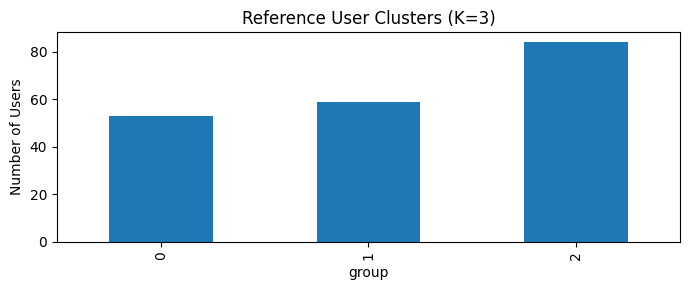

Reference users: 196
Matched future users: 145
Fixed-centroid agreement: 0.821
Future         0      1      2
Reference                     
0          0.854  0.122  0.024
1          0.070  0.837  0.093
2          0.098  0.115  0.787
   silhouette   inertia  smallest_group  largest_group  mean_seed_ARI  \
k                                                                       
2       0.219  1855.609              72            124          0.973   
3       0.247  1456.701              53             84          0.989   
4       0.212  1319.580              34             57          0.996   
5       0.201  1215.173              27             55          0.957   
6       0.189  1126.725              13             51          0.744   

   future_fixed_agreement  future_refit_ARI  future_silhouette  
k                                                               
2                   0.897            -0.008              0.198  
3                   0.821             0.531              0.

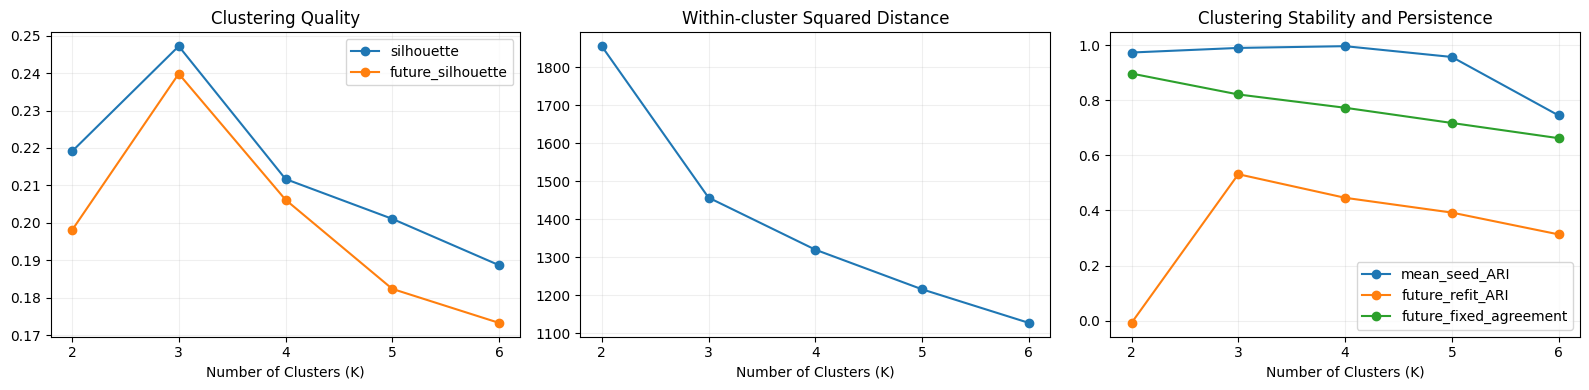

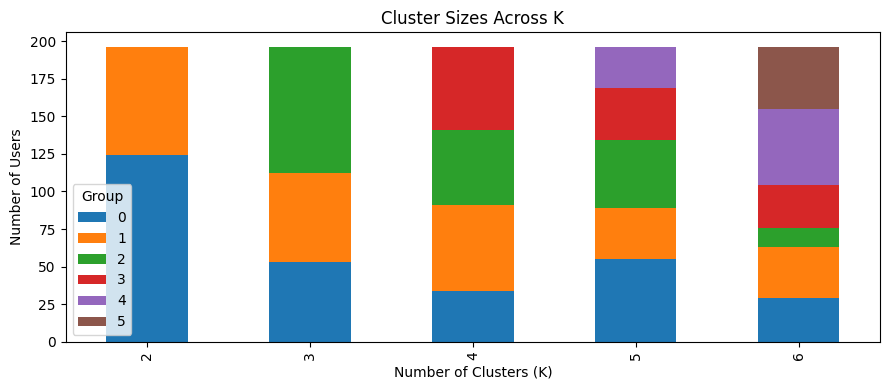

In [75]:
# K-means model selection

cluster_models = {}
cluster_scores = []

max_k = min(6, len(reference) - 1)

for k in range(2, max_k + 1):

    model = KMeans(n_clusters=k, random_state=42, n_init=20).fit(X)
    labels = model.labels_
    if len(np.unique(labels)) < 2:
        continue

    cluster_models[k] = model

    cluster_scores.append({ 
        "k": k,
        "silhouette": silhouette_score(X, labels),
        "inertia": model.inertia_
    })


cluster_scores = pd.DataFrame(cluster_scores).set_index("k")
print(cluster_scores.round(3))
best_k = cluster_scores["silhouette"].idxmax()
cluster_model = cluster_models[best_k]
print("Best K:", best_k)


# ============================================================
# 5. Reference cluster profiles
# ============================================================

reference["group"] = cluster_model.labels_
print("Reference cluster profiles:")

print(reference.groupby("group")[selected_features + ["session_count"]].mean().round(3))

reference["group"].value_counts().sort_index().plot.bar(
    figsize=(7, 3), ylabel="Number of Users", title=f"Reference User Clusters (K={best_k})")

plt.tight_layout()
plt.show()


# ============================================================
# 6. Future cluster assignment and transition
# ============================================================

future["group"] = cluster_model.predict(future_X)

print("Reference users:", len(reference))
print("Matched future users:", len(common))

if len(common) > 0:

    agreement = (
        reference.loc[common, "group"]
        .eq(future.loc[common, "group"])
        .mean()
    )

    print("Fixed-centroid agreement:", round(agreement, 3))

    transition = pd.crosstab(
        reference.loc[common, "group"],
        future.loc[common, "group"],
        normalize="index",
        rownames=["Reference"],
        colnames=["Future"]
    )

    print(transition.round(3))


# ============================================================
# 7. Compare all K solutions
# ============================================================

comparison = []
cluster_sizes = {}

user_groups = reference[selected_features + ["session_count"]].copy()

for k, model in cluster_models.items():
    labels = model.labels_

    sizes = pd.Series(labels).value_counts().sort_index()
    cluster_sizes[k] = sizes

    user_groups[f"group_k{k}"] = labels

    # Seed stability
    seed_ari = []

    for seed in [0, 1, 2]:

        alternative = KMeans(
            n_clusters=k,
            random_state=seed,
            n_init=20
        ).fit(X)

        seed_ari.append(
            adjusted_rand_score(
                labels, alternative.labels_
            )
        )

    # Future assignment using fixed reference centroids
    later_labels = model.predict(future_X)

    later_groups = pd.Series(later_labels, index=future.index)

    # Future fixed-centroid agreement
    fixed_agreement = (user_groups.loc[common, f"group_k{k}"].eq(later_groups.loc[common]).mean() if len(common) > 0 else np.nan)

    # Independent future clustering
    if len(future) >= k:

        later_refit_model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        ).fit(future_X)

        later_refit = pd.Series(
            later_refit_model.labels_,
            index=future.index
        )

        refit_ari = (
            adjusted_rand_score(
                user_groups.loc[common, f"group_k{k}"],
                later_refit.loc[common]
            )
            if len(common) >= 2 else np.nan
        )

    else:
        refit_ari = np.nan

    # Future silhouette: matched users only
    matched_X = future_X[
        future.index.get_indexer(common)
    ]

    matched_labels = later_groups.loc[common].to_numpy()

    future_silhouette = (
        silhouette_score(matched_X, matched_labels)
        if 1 < len(np.unique(matched_labels)) < len(common)
        else np.nan
    )

    comparison.append({
        "k": k,
        "silhouette": cluster_scores.loc[k, "silhouette"],
        "inertia": model.inertia_,
        "smallest_group": sizes.min(),
        "largest_group": sizes.max(),
        "mean_seed_ARI": np.mean(seed_ari),
        "future_fixed_agreement": fixed_agreement,
        "future_refit_ARI": refit_ari,
        "future_silhouette": future_silhouette
    })

    # Verify fitted distances and inertia
    distance = cdist(X, model.cluster_centers_)

# ============================================================
# 8. Comparison tables
# ============================================================

cluster_comparison = (pd.DataFrame(comparison).set_index("k"))

print(cluster_comparison.round(3))
cluster_sizes = (pd.DataFrame(cluster_sizes).T.fillna(0).astype(int))
cluster_sizes.index.name = "K"
cluster_sizes.columns.name = "Group"
print(cluster_sizes)

# ============================================================
# 9. Model comparison visualization
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

cluster_comparison[
    ["silhouette", "future_silhouette"]
].plot(
    marker="o",
    ax=axes[0],
    title="Clustering Quality"
)

cluster_comparison["inertia"].plot(
    marker="o",
    ax=axes[1],
    title="Within-cluster Squared Distance"
)

cluster_comparison[
    [
        "mean_seed_ARI",
        "future_refit_ARI",
        "future_fixed_agreement"
    ]
].plot(
    marker="o",
    ax=axes[2],
    title="Clustering Stability and Persistence"
)

for ax in axes:
    ax.set_xticks(cluster_comparison.index)
    ax.set_xlabel("Number of Clusters (K)")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


# ============================================================
# 10. Cluster size visualization
# ============================================================

cluster_sizes.plot.bar(
    stacked=True,
    figsize=(9, 4),
    ylabel="Number of Users",
    title="Cluster Sizes Across K"
)

plt.xlabel("Number of Clusters (K)")
plt.tight_layout()
plt.show()


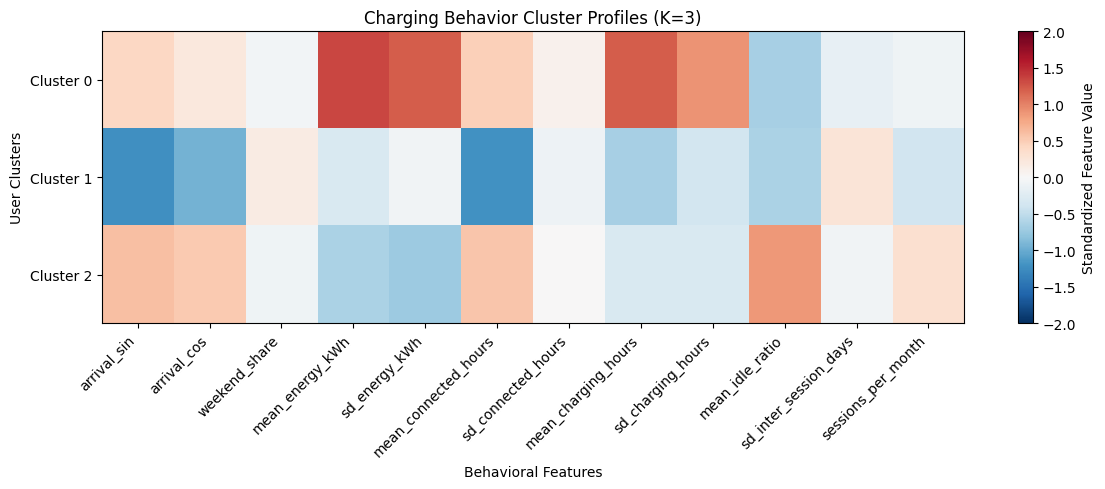

In [79]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Mean feature values by cluster
cluster_profiles = (
    reference.groupby("group")[selected_features]
    .mean()
)

# Standardize using reference-period user statistics
feature_mean = reference[selected_features].mean()
feature_std = reference[selected_features].std().replace(0, np.nan)

cluster_profiles_z = (
    (cluster_profiles - feature_mean) / feature_std
).fillna(0)

# Heatmap
fig, ax = plt.subplots(
    figsize=(max(12, len(selected_features) * 0.9), 5)
)

im = ax.imshow(
    cluster_profiles_z,
    cmap="RdBu_r",
    aspect="auto",
    vmin=-2,
    vmax=2
)

ax.set_xticks(range(len(selected_features)))
ax.set_xticklabels(selected_features, rotation=45, ha="right")

ax.set_yticks(range(len(cluster_profiles_z)))
ax.set_yticklabels(
    [f"Cluster {k}" for k in cluster_profiles_z.index]
)

ax.set_title(f"Charging Behavior Cluster Profiles (K={best_k})")
ax.set_xlabel("Behavioral Features")
ax.set_ylabel("User Clusters")

plt.colorbar(im, ax=ax, label="Standardized Feature Value")
plt.tight_layout()
plt.show()

Cluster 0 High-demand, Long-stay Users
平均充电量高、充电量波动大、充电完成耗时较长，且平均连接时间也较长。空闲时间占比偏低，说明连接时间中用于完成充电的比例相对较高。

Cluster 1 Low-demand, Short-stay Users
平均充电量较低、连接时间较短，充电完成耗时也较短。整体充电需求偏低，空闲时间占比略低于平均水平。

Cluster 2 Low-demand, High-idle-ratio Users
平均充电量较低，但连接时间高于 Cluster 1，充电完成后的空闲时间占比明显最高。这类用户可能具有更大的充电时间调整空间，但还需要结合实际充电功率和约束验证。

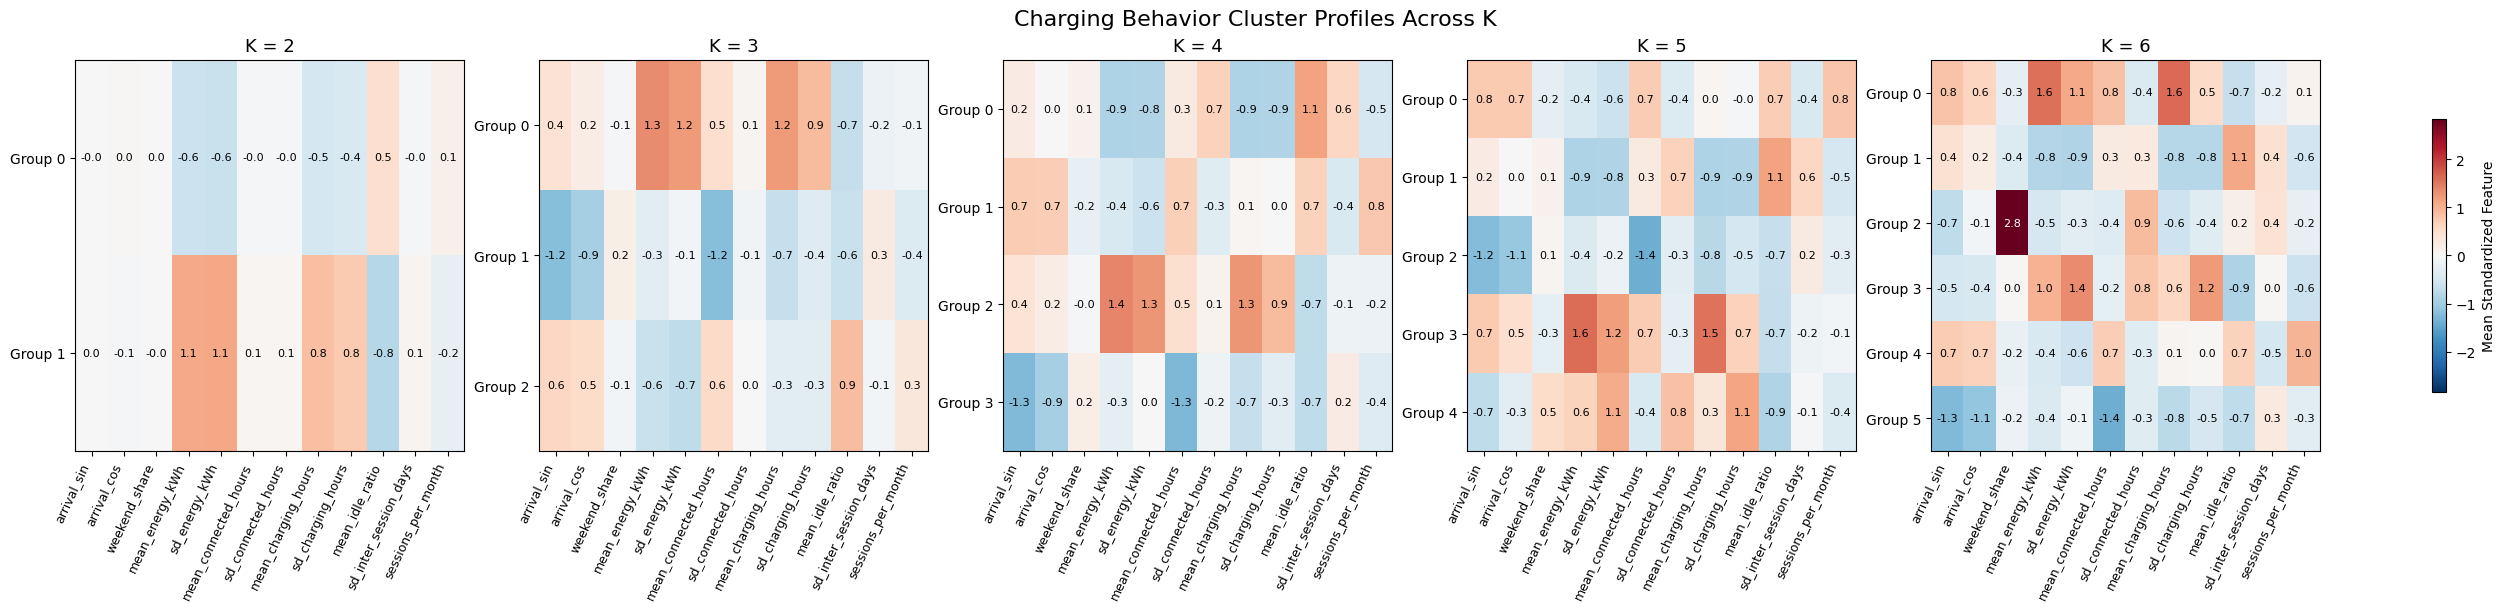

         arrival_sin  arrival_cos  weekend_share  mean_energy_kWh  \
K group                                                             
2 0             0.46        -0.42           0.02             9.23   
  1             0.47        -0.44           0.02            25.75   
3 0             0.68        -0.38           0.02            28.35   
  1            -0.17        -0.64           0.03            12.32   
  2             0.77        -0.30           0.02             9.15   
4 0             0.59        -0.42           0.03             6.68   
  1             0.84        -0.26           0.01            11.13   
  2             0.67        -0.38           0.02            28.81   
  3            -0.19        -0.64           0.03            12.66   
5 0             0.86        -0.26           0.01            11.11   
  1             0.59        -0.42           0.03             6.68   
  2            -0.19        -0.67           0.02            11.21   
  3             0.85        -0.32 

In [ ]:
profile_tables = {}
standardized_profiles = {}

for k, model in cluster_models.items():

    # Raw feature means
    profile_tables[k] = (reference[selected_features].assign(group=model.labels_).groupby("group").mean())
    # Standardized feature means
    standardized_profiles[k] = (pd.DataFrame( X, columns=selected_features, index=reference.index).assign(group=model.labels_).groupby("group").mean())

# Shared color scale
limit = max(np.abs(table.to_numpy()).max() for table in standardized_profiles.values())

# ============================================================
# Heatmaps
# ============================================================

fig, axes = plt.subplots(
    1,
    len(cluster_models),
    figsize=(5 * len(cluster_models), 6),
    constrained_layout=True,
    squeeze=False
)

axes = axes.ravel()

for ax, (k, table) in zip(axes, standardized_profiles.items()):

    plot = ax.imshow(table, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
    ax.set_title(f"K = {k}", fontsize=13)
    ax.set_xticks(range(len(selected_features)))
    ax.set_xticklabels(
        selected_features,
        rotation=65,
        ha="right",
        fontsize=9
    )

    ax.set_yticks(range(len(table)))
    ax.set_yticklabels(
        [f"Group {g}" for g in table.index]
    )

    # Display values inside cells
    for row in range(len(table)):
        for column in range(len(selected_features)):

            value = table.iloc[row, column]

            ax.text(
                column,
                row,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if abs(value) > limit * 0.6 else "black"
            )

fig.colorbar(plot, ax=list(axes), label="Mean Standardized Feature", shrink=0.7)

fig.suptitle("Charging Behavior Cluster Profiles Across K", fontsize=16)

plt.show()


# ============================================================
# Raw feature means and cluster sizes
# ============================================================

profile_summary = pd.concat(profile_tables,names=["K", "group"])

# Number of users in each cluster
profile_summary["users"] = pd.Series({
    (k, g): count
    for k, model in cluster_models.items()
    for g, count in pd.Series(model.labels_).value_counts().items()
})

print(profile_summary.round(2))

**Figure interpretation — standardized user profiles.** Colors represent feature means relative to the same reference-user standardization, allowing comparison across K. At K=3, the early-arrival/long-connection pattern splits into groups with mean energy of approximately 30.82 and 9.91 kWh, despite similar mean connection durations around 8.3–8.4 hours. Thus, similar connection schedules need not imply similar energy requirements. Cluster numbers are not aligned across K.

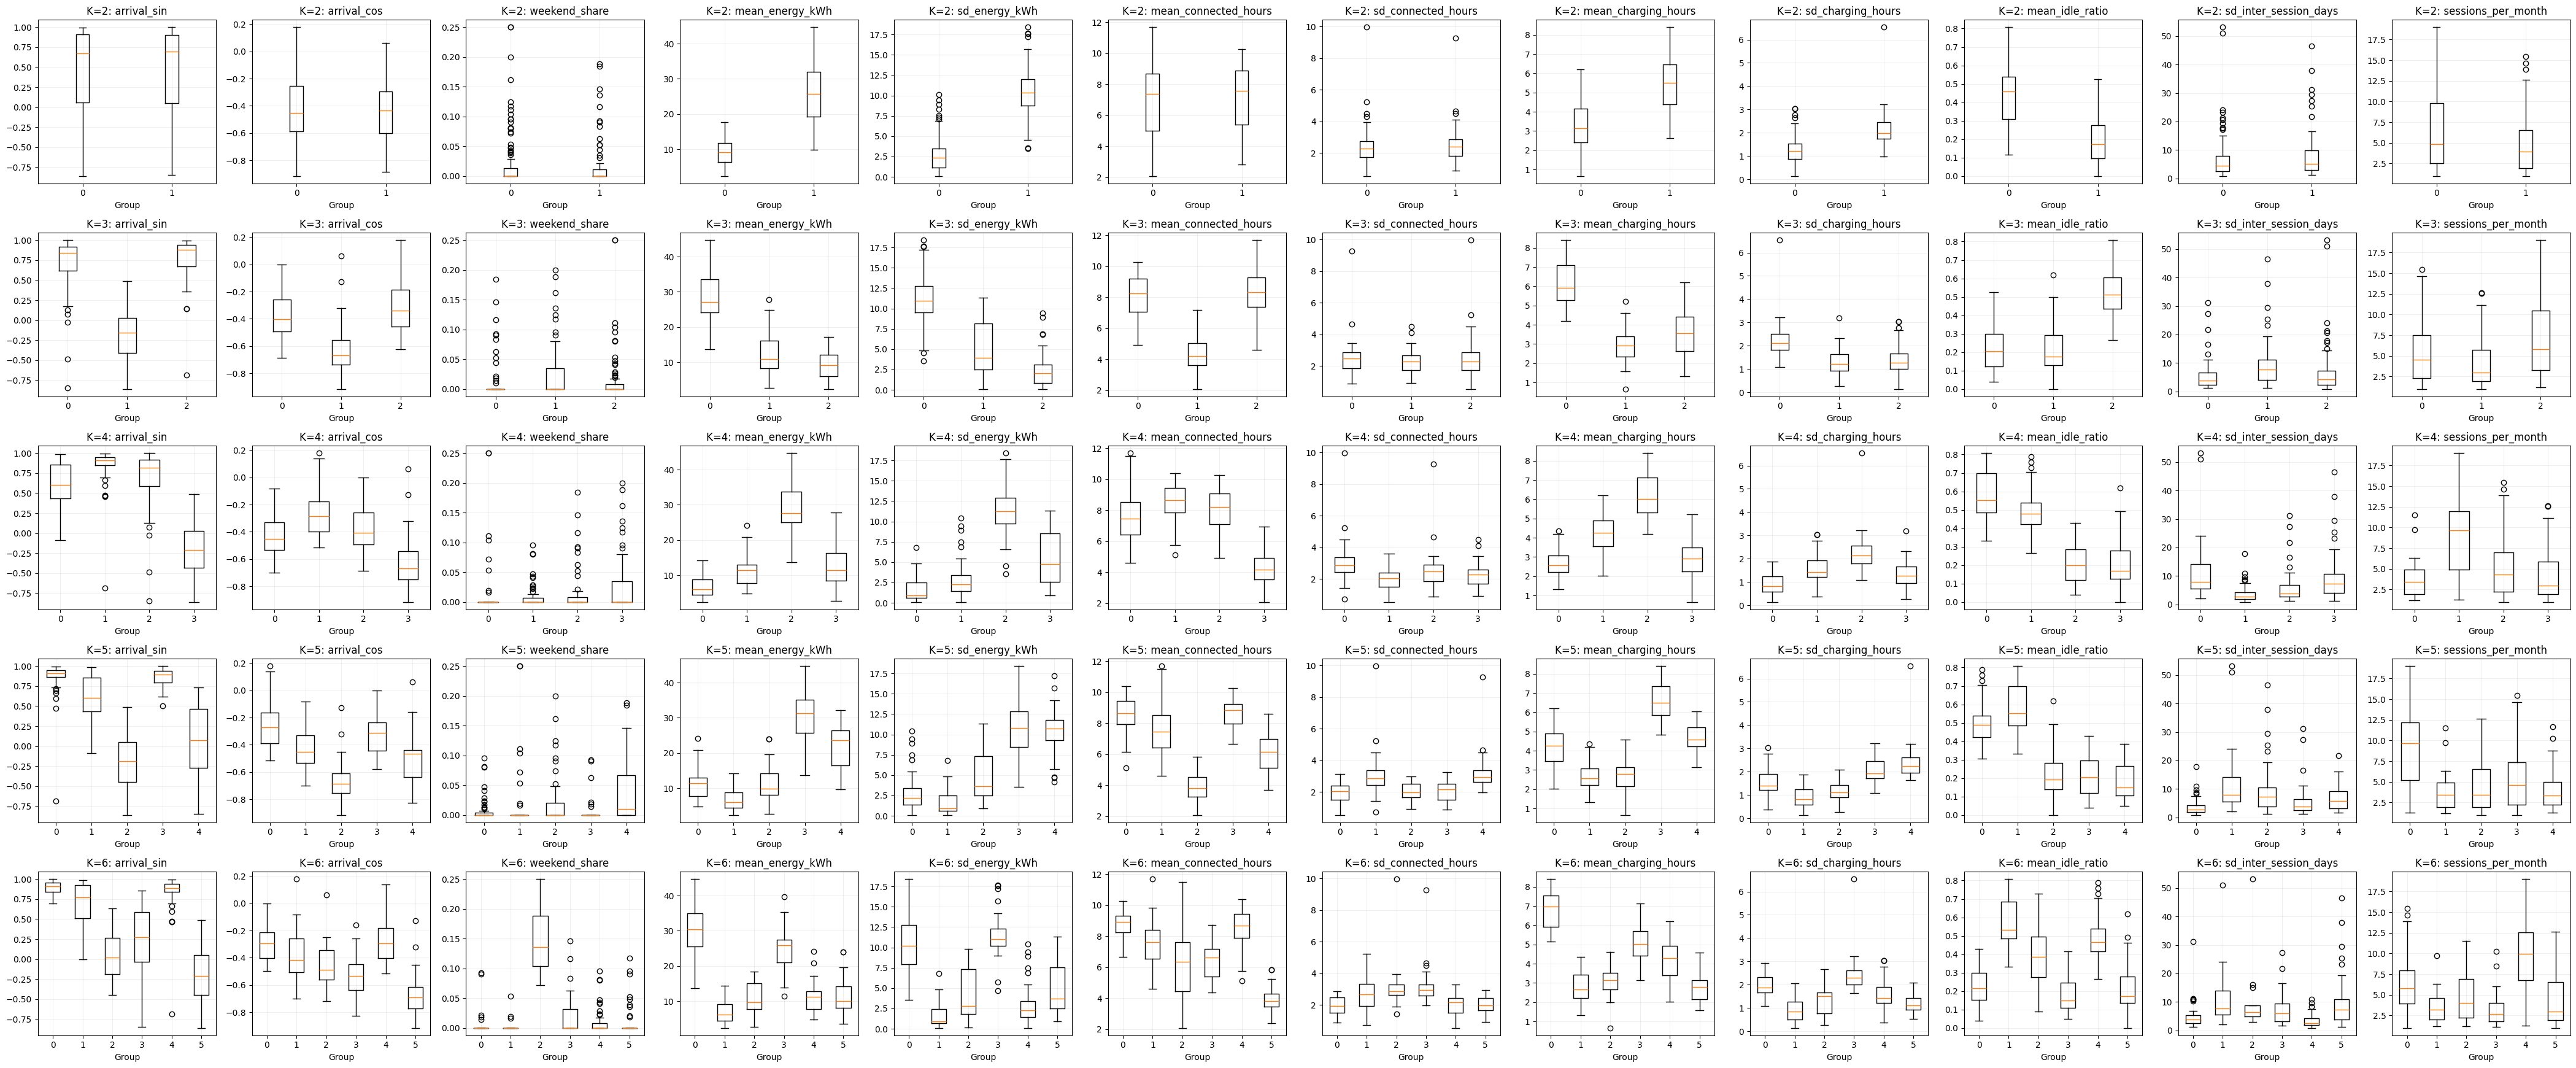

Users: 196 Reference period: 2018-09-01 to 2019-07-01
           arrival_sin  arrival_cos  weekend_share  mean_energy_kWh  \
userID                                                                
000000531     0.778747    -0.495094       0.000000        23.453871   
000000741    -0.022413    -0.661949       0.083333        32.222000   
000000730     0.921168    -0.260471       0.000000        39.386571   
000000631     0.632217    -0.462871       0.146341        26.795416   
000000611     0.953478    -0.211860       0.000000        44.656196   
...                ...          ...            ...              ...   
000000371     0.860124    -0.265323       0.000000        11.799125   
000000756     0.620451    -0.561584       0.111111        10.642767   
000000742     0.700883    -0.582473       0.000000         2.408219   
000000374     0.733862    -0.483177       0.006579         7.729151   
000000386     0.444675    -0.478527       0.000000         5.948907   

           sd_energy_k

In [85]:
# Distribution overlap across all K and clustering features
box_features = selected_features

fig, axes = plt.subplots(
    len(cluster_models),
    len(box_features),
    figsize=(3.5 * len(box_features), 3.5 * len(cluster_models)),
    squeeze=False
)

for row, (k, model) in enumerate(cluster_models.items()):
    for column, feature in enumerate(box_features):
        ax = axes[row, column]

        values = [
            reference.loc[model.labels_ == group, feature]
            .dropna()
            for group in range(k)
        ]

        ax.boxplot(
            values,
            labels=list(range(k)),
            showfliers=True
        )

        ax.set_title(f"K={k}: {feature}")
        ax.set_xlabel("Group")
        ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


# All eligible reference users and assignments under every K
print(
    "Users:", len(user_groups),
    "Reference period:",
    reference_start.date(),
    "to", reference_end.date()
)

print(user_groups.sort_values(f"group_k{best_k}"))

print(
    "Silhouette-based candidate K:", best_k,
    "— downstream analyses retain this candidate until the comparison is reviewed."
)

**Figure interpretation — within-group distributions.** Each row uses a different K; columns compare duration, energy, recorded frequency and weekend share. Boxes describe medians and interquartile ranges, while displayed outliers reveal long tails. Use these distributions to assess overlap rather than interpreting different group means as perfect separation. Finer groups may reveal additional heterogeneity but require adequate sample sizes and temporal validation.

### Selected behavioral groups

This exploratory analysis retains K=2: it has the highest reference-period silhouette (0.317), with 72 and 124 users. Mean agreement with the reference solution across three alternative random seeds is ARI=1.000. Among 145 matched users in the later period, fixed-centroid label agreement is 90.3%. Temporal stability is supplementary evidence, not confirmation of true latent user types.

K=3–5 provides finer distinctions in energy, visit frequency and weekend use and remains available for sensitivity analysis. K=2 is the current parsimonious baseline, not evidence that only two user types exist. The labels describe observed behavior at site 1; they do not establish occupation, trip purpose, psychological preferences or activity at other charging sites.

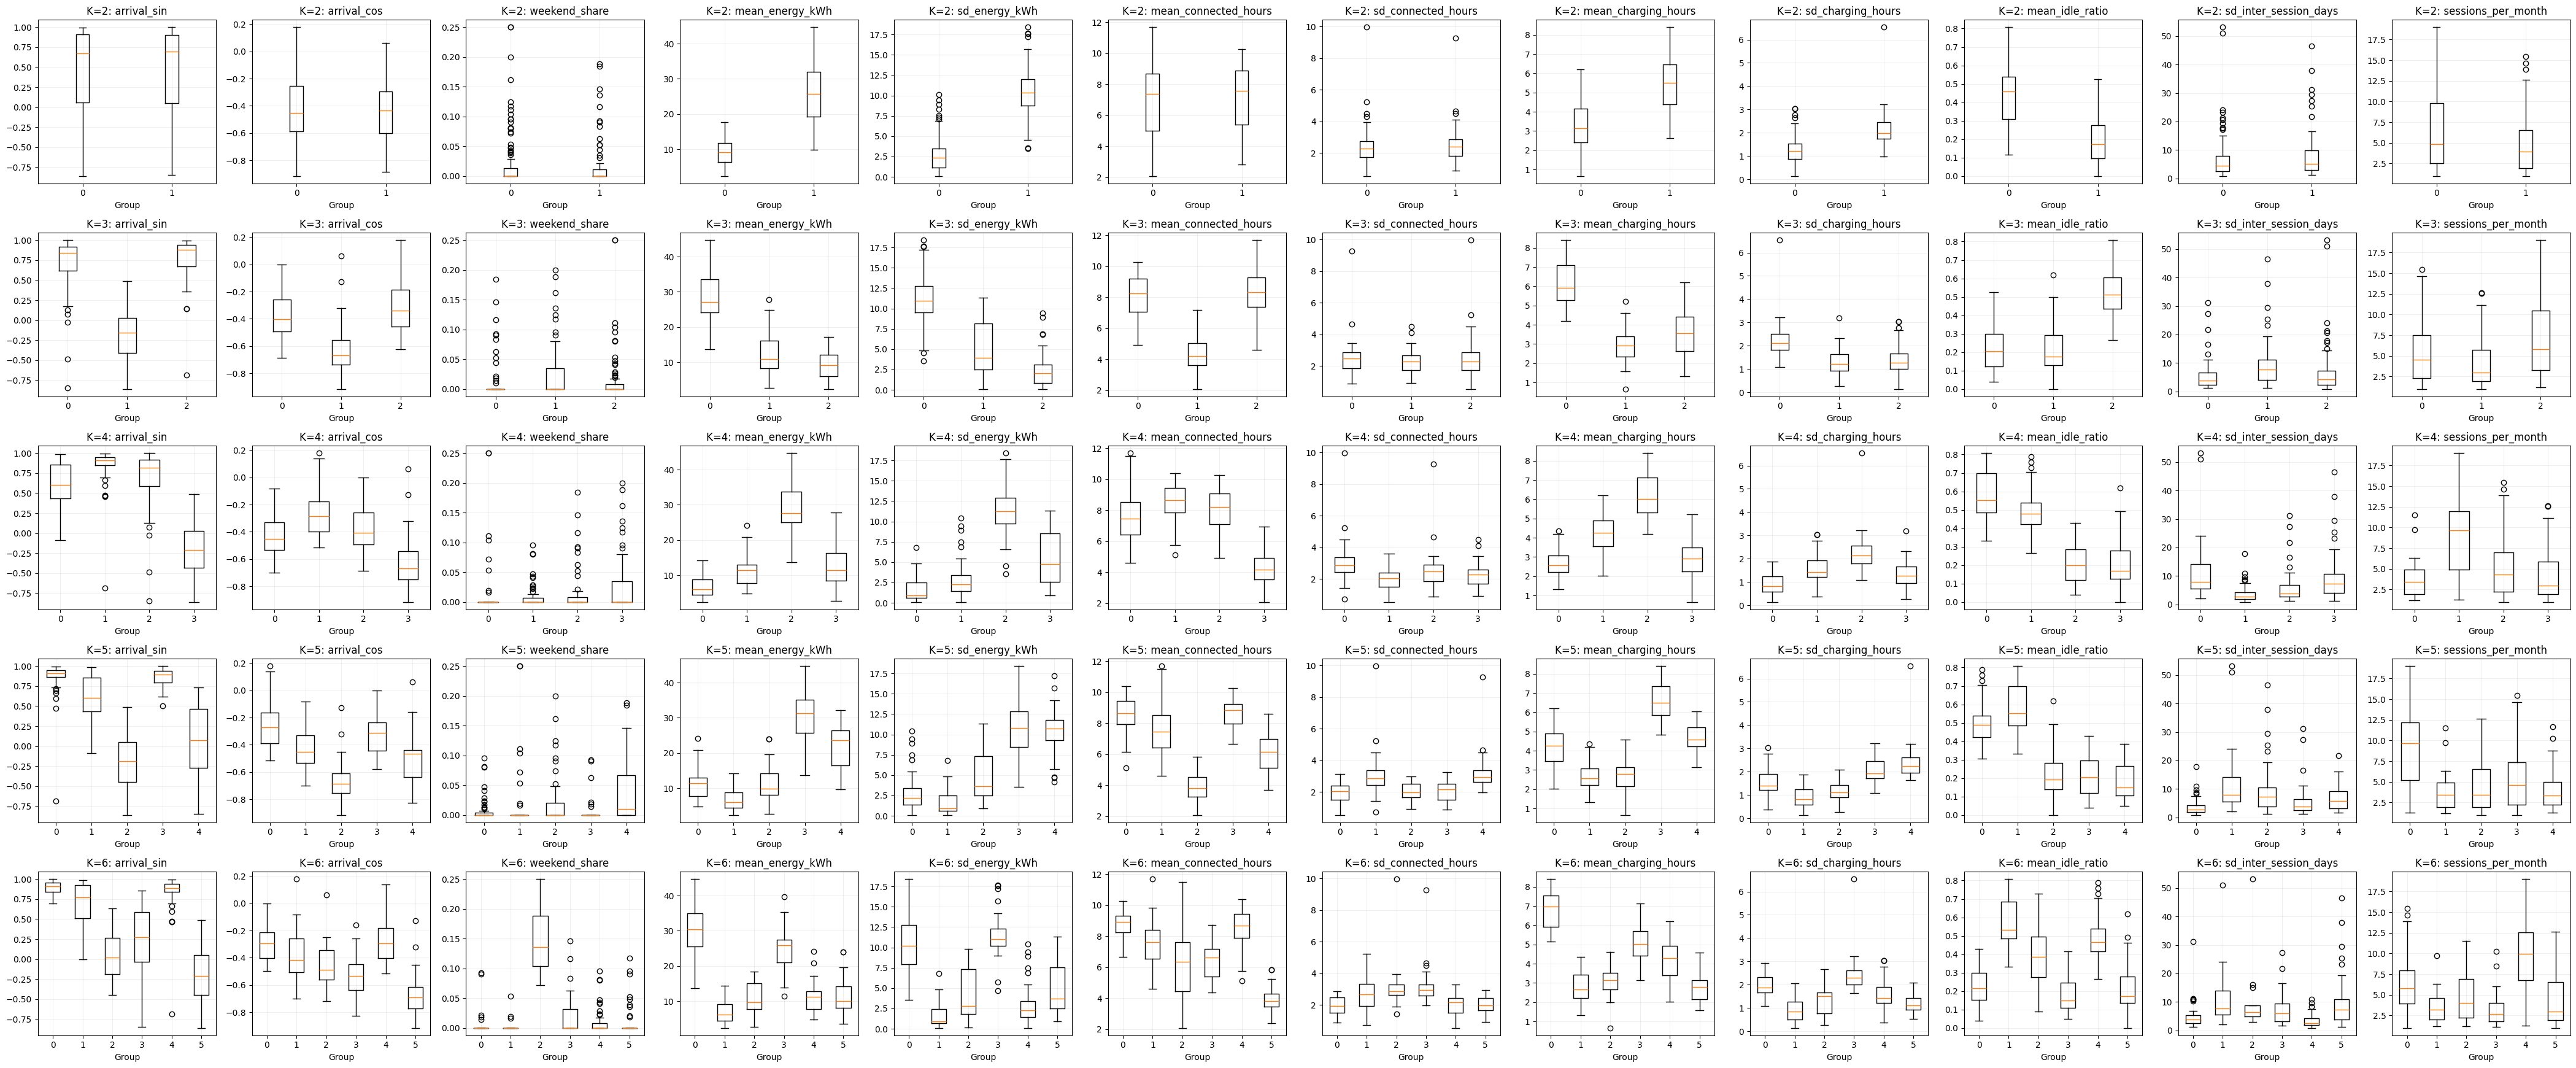

Users: 196 Reference period: 2018-09-01 to 2019-07-01
           arrival_sin  arrival_cos  weekend_share  mean_energy_kWh  \
userID                                                                
000000531     0.778747    -0.495094       0.000000        23.453871   
000000741    -0.022413    -0.661949       0.083333        32.222000   
000000730     0.921168    -0.260471       0.000000        39.386571   
000000631     0.632217    -0.462871       0.146341        26.795416   
000000611     0.953478    -0.211860       0.000000        44.656196   
...                ...          ...            ...              ...   
000000371     0.860124    -0.265323       0.000000        11.799125   
000000756     0.620451    -0.561584       0.111111        10.642767   
000000742     0.700883    -0.582473       0.000000         2.408219   
000000374     0.733862    -0.483177       0.006579         7.729151   
000000386     0.444675    -0.478527       0.000000         5.948907   

           sd_energy_k

In [ ]:
# Explain the selected solution in original units (equal weight per user).
selected_k = best_k
selected_profiles = reference[profile_features].assign(
    group=cluster_models[selected_k].labels_
).groupby("group").mean()
selected_profiles["users"] = pd.Series(cluster_models[selected_k].labels_).value_counts()
selected_profiles["share_pct"] = selected_profiles["users"] / len(reference) * 100
selected_profiles["arrival_hour_circular"] = (
    np.arctan2(selected_profiles["arrival_sin"], selected_profiles["arrival_cos"])
    % (2 * np.pi)
) * 24 / (2 * np.pi)
selected_profiles["arrival_concentration"] = np.hypot(
    selected_profiles["arrival_sin"], selected_profiles["arrival_cos"]
)
selected_profiles["weekend_pct"] = selected_profiles["weekend"] * 100

# Names are relative descriptions; cluster numbers themselves carry no meaning.
if selected_k == 2:
    short_group = selected_profiles["duration"].idxmin()
    long_group = selected_profiles["duration"].idxmax()
    group_names = {
        short_group: "Later arrival / shorter connection / less frequent visits",
        long_group: "Morning arrival / longer connection / more frequent visits"
    }
else:
    group_names = {group: f"Behavioral group {group}" for group in selected_profiles.index}
selected_profiles.insert(0, "behavior_label", selected_profiles.index.map(group_names))
display_table(selected_profiles[["behavior_label", "users", "share_pct", "arrival_hour_circular",
    "arrival_concentration", "duration", "energy", "frequency", "weekend_pct"]].round(2))
reference["behavior_label"] = reference["group"].map(group_names)
user_groups["selected_group"] = reference["group"]
user_groups["behavior_label"] = reference["behavior_label"]
with pd.option_context("display.max_rows", None):
    display_table(user_groups.sort_values("selected_group"))

**Group 0: Later arrival, shorter connection, less frequent visits (72 users; 36.7%).** Average connection duration is 4.57 hours, delivered energy is 13.19 kWh per session, and recorded visit frequency is 4.16 sessions per month. The circular mean arrival time is approximately 12:41, with concentration 0.63. Arrival times are comparatively dispersed; the mean does not imply that every user arrives at noon.

**Group 1: Morning arrival, longer connection, more frequent visits (124 users; 63.3%).** Average connection duration is 8.38 hours, delivered energy is 16.52 kWh per session, and recorded visit frequency is 6.81 sessions per month. The circular mean arrival time is approximately 07:25, with concentration 0.86. This pattern is compatible with extended weekday parking, but occupation and trip purpose are not observed.

**The main distinctions are arrival timing, connection duration and recorded visit frequency.** Both groups predominantly use the site on weekdays: their mean weekend session shares are 2.44% and 1.74%. Weekend use is therefore not a defining distinction between these two groups. Different mean energy values do not imply non-overlapping distributions; inspect the boxplots alongside the means.

All summaries weight users equally. Arrival concentration is the length of the mean sine/cosine vector, ranging from 0 to 1; it reflects both within-user and between-user timing variation, not a psychological score. Connection duration is not active charging duration, and visit frequency excludes other sites. These interpretations correspond to the current run and should be reviewed if the data or K changes.

In [ ]:
# Future energy prediction: same test users and sessions for all baselines.
reference_sessions = users.loc[
    users["date"].ge(reference_start) & users["date"].lt(reference_end)
].join(reference["group"], on="userID").dropna(subset=["group"])
group_energy = reference_sessions.groupby("group")["kWhDelivered"].mean()
test_users = users.loc[
    users["date"].ge(stability_end) & users["date"].lt(test_end)
    & users["userID"].isin(reference.index)
].copy()
predictions = {
    "Global mean": np.repeat(reference_sessions["kWhDelivered"].mean(), len(test_users)),
    "Group mean": test_users["userID"].map(reference["group"]).map(group_energy),
    "Personal mean": test_users["userID"].map(reference["energy"])
}
rq1_scores = []
for name, prediction in predictions.items():
    error = pd.Series(np.abs(test_users["kWhDelivered"].to_numpy() - np.asarray(prediction)),
                      index=test_users.index)
    rq1_scores.append({"model": name, "session_MAE_kWh": error.mean(),
                       "user_macro_MAE_kWh": error.groupby(test_users["userID"]).mean().mean()})
print("Test sessions:", len(test_users), "Test users:", test_users["userID"].nunique())
display_table(pd.DataFrame(rq1_scores).set_index("model"))

Test sessions: 3078 Test users: 161


,session_MAE_kWh,user_macro_MAE_kWh
model,,
Global mean,8.312237,9.191978
Group mean,8.251816,9.010026
Personal mean,4.570294,5.431058


**Prediction finding — user history versus coarse groups.** On the same 3,078 test sessions from 161 reference users, MAE is 8.31 kWh for the global mean, 8.25 for group means and 4.57 for personal historical means. Group means improve little, whereas personal history reduces session-weighted MAE by about 45% relative to the global mean. The two-group description therefore retains limited information for energy prediction; substantial heterogeneity remains within groups. This result applies to previously observed eligible users, not new or anonymous users.

## RQ1 main analysis — Separate session clustering by site

The earlier analysis clusters identified users at site 1 only. This section independently clusters charging sessions at each site, including anonymous sessions. A session type is not a user type: one person can generate several session types. Both sites use the same reference dates and features, but separate scalers, centroids and K selection. Cluster numbers are not aligned across sites.

Connection duration and delivered energy are log-transformed before scaling to reduce the influence of long-tailed values. Silhouettes use the same fixed sample of up to 2,000 sessions within each site for all K. These are descriptive reference-period clusters, not predictions or causal explanations. Session proportions weight frequent users more heavily.

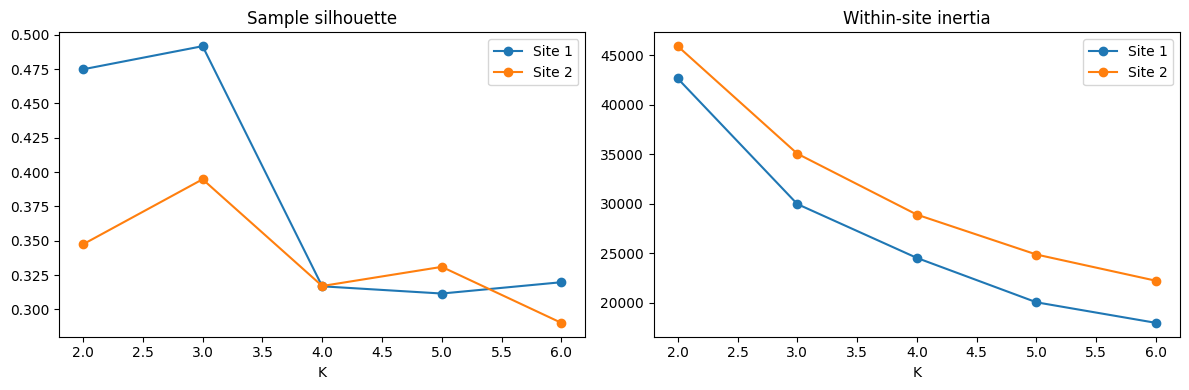

In [ ]:
# Independent session models: no user ID or combined-site fitting.
site_models = {}
site_profiles = {}
site_assignments = {}
site_candidates = []
session_features = ["arrival_sin", "arrival_cos", "weekend", "log_duration", "log_energy"]
for site in [1, 2]:
    data = sessions.loc[
        sessions["siteID"].eq(site)
        & sessions["date"].ge(reference_start) & sessions["date"].lt(reference_end)
        & sessions["connected_duration_hours"].gt(0)
    ].copy()
    data["log_duration"] = np.log1p(data["connected_duration_hours"])
    data["log_energy"] = np.log1p(data["kWhDelivered"])
    site_scaler = StandardScaler()
    values = site_scaler.fit_transform(data[session_features])
    rng = np.random.default_rng(42)
    sample = rng.choice(len(data), size=min(2000, len(data)), replace=False)
    distances = cdist(values[sample], values[sample])
    candidates = {}
    for k in range(2, 7):
        model = KMeans(n_clusters=k, init="random", n_init=20, random_state=42).fit(values)
        candidates[k] = model
        counts = np.bincount(model.labels_, minlength=k)
        score = silhouette_score(distances, model.labels_[sample], metric="precomputed")
        site_candidates.append({"site": site, "k": k, "silhouette": score,
                                "inertia": model.inertia_, "smallest_cluster": counts.min(),
                                "largest_cluster": counts.max()})
    scores = pd.DataFrame(site_candidates).query("site == @site")
    selected = int(scores.loc[scores["silhouette"].idxmax(), "k"])
    model = candidates[selected]
    data["session_group"] = model.labels_
    site_models[site] = {"k": selected, "scaler": site_scaler, "model": model}
    profile = data.groupby("session_group").agg(
        sessions=("sessionID", "size"), arrival_sin=("arrival_sin", "mean"),
        arrival_cos=("arrival_cos", "mean"), weekend_share=("weekend", "mean"),
        mean_connected_hours=("connected_duration_hours", "mean"),
        median_connected_hours=("connected_duration_hours", "median"),
        mean_energy_kWh=("kWhDelivered", "mean"), median_energy_kWh=("kWhDelivered", "median")
    )
    profile["share_pct"] = profile["sessions"] / len(data) * 100
    profile["circular_arrival_hour"] = np.arctan2(profile["arrival_sin"], profile["arrival_cos"]) % (2*np.pi) * 24/(2*np.pi)
    profile["arrival_concentration"] = np.hypot(profile["arrival_sin"], profile["arrival_cos"])
    descriptions = {}
    for group, row in profile.iterrows():
        hour = row["circular_arrival_hour"]
        timing = "morning" if 5 <= hour < 12 else "afternoon" if 12 <= hour < 18 else "evening/night"
        if row["arrival_concentration"] < 0.4:
            timing = "dispersed arrival times"
        duration = "longer connections" if row["median_connected_hours"] >= data["connected_duration_hours"].median() else "shorter connections"
        energy = "higher delivered energy" if row["median_energy_kWh"] >= data["kWhDelivered"].median() else "lower delivered energy"
        day = "mostly weekdays" if row["weekend_share"] < 0.2 else "mostly weekends" if row["weekend_share"] > 0.8 else "mixed weekdays/weekends"
        descriptions[group] = f"{timing}; {duration}; {energy}; {day}"
    profile["behavior_description"] = pd.Series(descriptions)
    data["behavior_description"] = data["session_group"].map(descriptions)
    site_profiles[site] = profile
    site_assignments[site] = data

site_comparison = pd.DataFrame(site_candidates).set_index(["site", "k"])
display_table(site_comparison.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for site in [1, 2]:
    result = site_comparison.loc[site]
    axes[0].plot(result.index, result["silhouette"], marker="o", label=f"Site {site}")
    axes[1].plot(result.index, result["inertia"], marker="o", label=f"Site {site}")
for ax, title in zip(axes, ["Sample silhouette", "Within-site inertia"]):
    ax.set_title(title)
    ax.set_xlabel("K")
    ax.legend()
plt.tight_layout()
plt.show()

**Figure interpretation — independent site-level K selection.** Both sites select K=3 within the tested range. Sample silhouettes are 0.492 at site 1 and 0.395 at site 2. Each site's curve uses its own fixed evaluation sample and scaler; absolute inertia is not a direct measure of which site has a better model. The weekend feature strongly affects the partition, so a feature-weight or weekend-exclusion sensitivity analysis is needed before interpreting the three groups as robust latent types.

Site 1: K=3, sessions=13385
Descriptions are relative to this site's median duration and energy.


,sessions,weekend_share,mean_connected_hours,median_connected_hours,mean_energy_kWh,median_energy_kWh,share_pct,circular_arrival_hour,arrival_concentration,behavior_description
session_group,,,,,,,,,,
0,9308,0.0,8.85,9.33,15.16,11.82,69.54,7.06,0.96,morning; longer connections; higher delivered energy; mostly weekdays
1,3753,0.0,3.39,3.07,9.96,8.18,28.04,13.84,0.78,afternoon; shorter connections; lower delivered energy; mostly weekdays
2,324,1.0,4.45,3.97,11.42,9.56,2.42,11.33,0.65,morning; shorter connections; lower delivered energy; mostly weekends


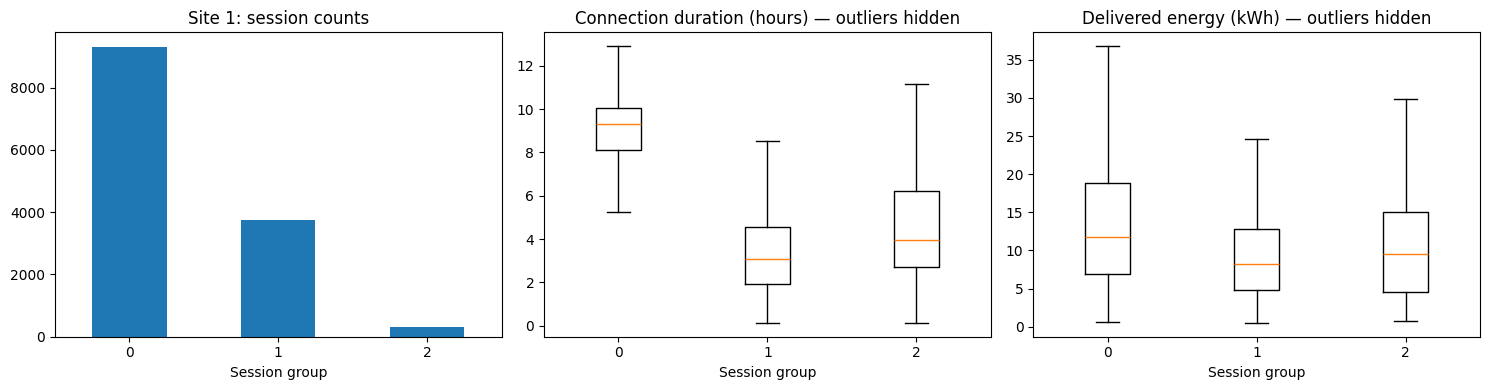

Site 2: K=3, sessions=12677
Descriptions are relative to this site's median duration and energy.


,sessions,weekend_share,mean_connected_hours,median_connected_hours,mean_energy_kWh,median_energy_kWh,share_pct,circular_arrival_hour,arrival_concentration,behavior_description
session_group,,,,,,,,,,
0,1979,1.0,4.36,2.29,9.80,7.30,15.61,13.36,0.51,afternoon; shorter connections; higher delivered energy; mostly weekends
1,7942,0.0,7.24,7.59,9.24,7.03,62.65,9.55,0.88,morning; longer connections; higher delivered energy; mostly weekdays
2,2756,0.0,4.08,1.97,8.56,6.36,21.74,18.29,0.81,evening/night; shorter connections; lower delivered energy; mostly weekdays


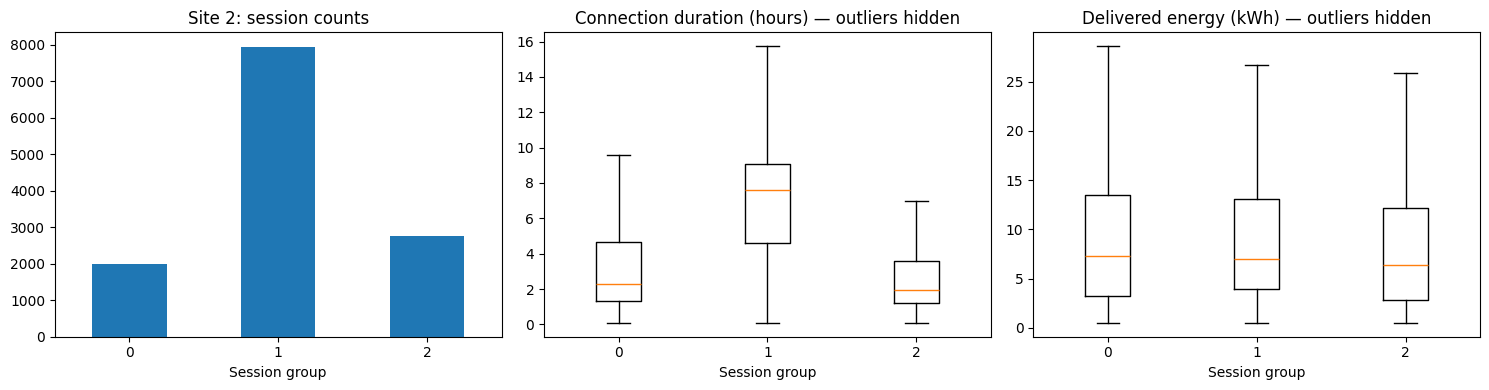

In [ ]:
# Results and behavioral descriptions shown separately for each site.
for site in [1, 2]:
    profile = site_profiles[site]
    data = site_assignments[site]
    print(f"Site {site}: K={site_models[site]['k']}, sessions={len(data)}")
    print("Descriptions are relative to this site's median duration and energy.")
    with pd.option_context("display.max_colwidth", None):
        display_table(profile.drop(columns=["arrival_sin", "arrival_cos"]).round(2))
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    profile["sessions"].plot.bar(ax=axes[0], title=f"Site {site}: session counts", rot=0)
    for ax, feature, title in [(axes[1], "connected_duration_hours", "Connection duration (hours)"),
                                (axes[2], "kWhDelivered", "Delivered energy (kWh)")]:
        groups = [data.loc[data["session_group"].eq(group), feature] for group in profile.index]
        ax.boxplot(groups, labels=profile.index.tolist(), showfliers=False)
        ax.set_title(title + " — outliers hidden")
    for ax in axes:
        ax.set_xlabel("Session group")
    plt.tight_layout()
    plt.show()

# Side-by-side comparison in original units; labels are site-specific.
site_profile_comparison = pd.concat(site_profiles, names=["site", "session_group"])
display_table(site_profile_comparison[["sessions", "share_pct", "circular_arrival_hour",
    "arrival_concentration", "median_connected_hours", "median_energy_kWh", "weekend_share"]].round(2))
# All assignments remain available in site_assignments[1] and site_assignments[2].

**Figure interpretation — separate session types.**

- **Site 1:** weekday morning/long-connection sessions account for 69.54%, weekday afternoon/shorter sessions for 28.04%, and weekend sessions for 2.42%. Median connection durations are 9.33, 3.07 and 3.97 hours, respectively.
- **Site 2:** weekday morning/long-connection sessions account for 62.65%, weekday evening/shorter sessions for 21.74%, and weekend sessions for 15.61%. Median durations are 7.59, 1.97 and 2.29 hours, respectively.

Bars count sessions, not unique people. Boxplots compare original-unit distributions; outlier markers are hidden for readability but observations remain in the analysis. The sites share an early-arrival/long-connection pattern, while non-morning timing and weekend shares differ. A weekend cluster partly reflects the explicitly included weekday/weekend feature.

### How to interpret the site-specific results

Read each site's selected K, cluster sizes, original-unit profiles and descriptions together. The labels summarize observed session characteristics; they do not identify occupations, motives, unique people or battery needs. Duration and energy labels compare cluster medians with the corresponding whole-site median, so they are relative rather than universal thresholds.

The two sites have independent feature scaling and cluster boundaries. Group 0 at site 1 is not necessarily equivalent to Group 0 at site 2. Compare the original-unit profiles rather than matching group numbers. Rare weekend sessions can form a separate cluster after standardization; inspect weekend shares and cluster sizes before claiming a substantively distinct behavioral type. The selected K remains exploratory and should be checked across time windows.

## RQ2 — Temporal changes in session types at each site

Assign later sessions using each site's fixed reference-period scaler and centroids. Plot monthly type shares and within-type median energy and connection duration. These are changes in observed sessions, not movements of identified users. Missing months remain missing. The first and last months can have partial coverage; recorded-month completeness is not guaranteed. The user-level analysis below is supplementary and applies only to identified site 1 users.

Site 1: monthly session counts by fixed type


session_group,0,1,2
2018-09,570.0,279.0,26.0
2018-10,1095.0,427.0,34.0
2018-11,907.0,350.0,27.0
2018-12,747.0,296.0,17.0
2019-01,1002.0,347.0,22.0
2019-02,916.0,349.0,23.0
2019-03,974.0,389.0,36.0
2019-04,1062.0,442.0,20.0
2019-05,1066.0,499.0,79.0
2019-06,969.0,375.0,40.0


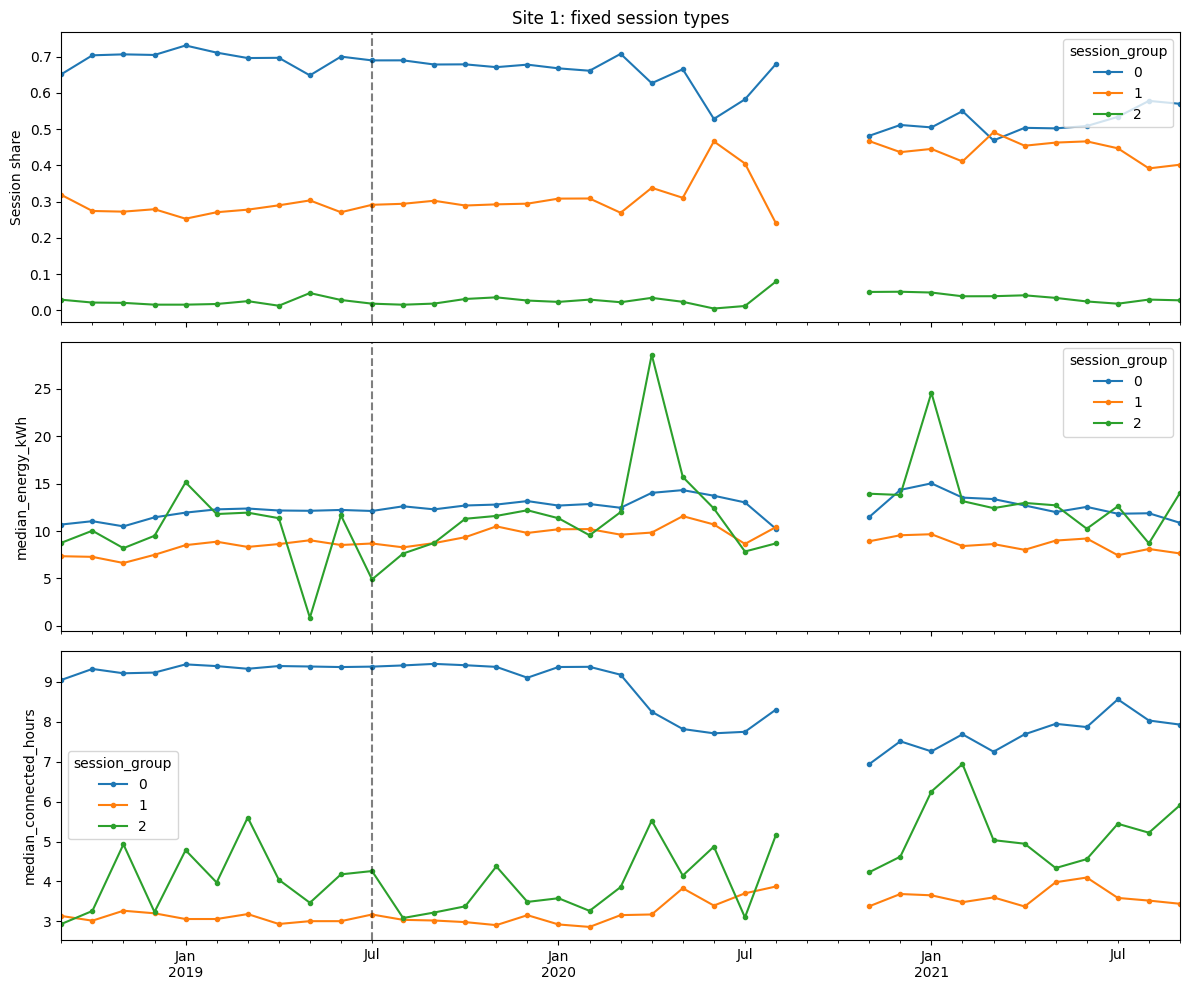

Site 2: monthly session counts by fixed type


session_group,0,1,2
2018-09,520.0,1152.0,643.0
2018-10,410.0,1299.0,715.0
2018-11,185.0,901.0,223.0
2018-12,153.0,566.0,151.0
2019-01,124.0,695.0,170.0
2019-02,125.0,620.0,189.0
2019-03,134.0,632.0,188.0
2019-04,127.0,714.0,194.0
2019-05,104.0,710.0,150.0
2019-06,97.0,653.0,133.0


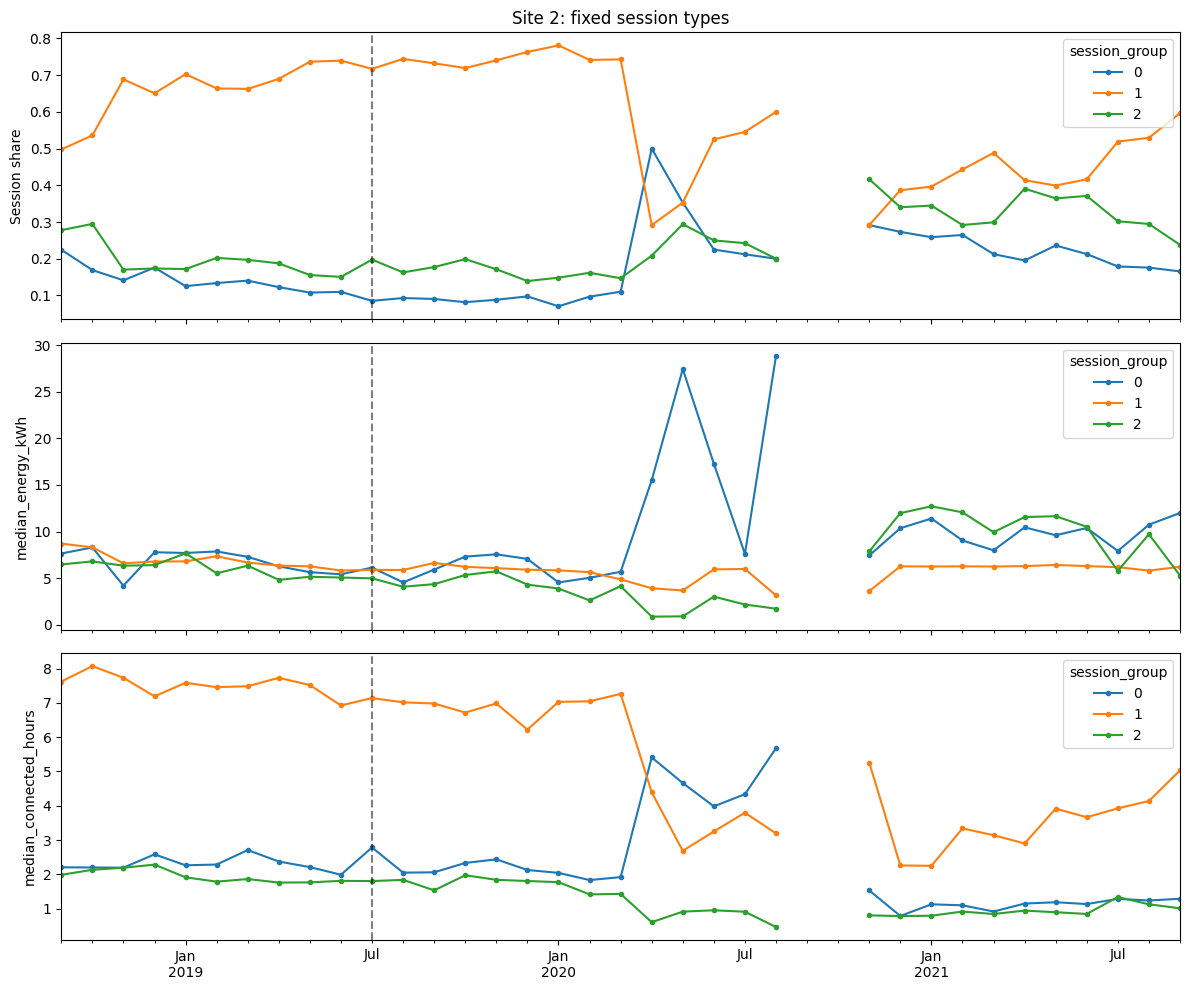

In [ ]:
# Fixed site-specific session types over time; no refitting on future months.
site_history = {}
site_monthly = {}
for site in [1, 2]:
    data = sessions.loc[sessions["siteID"].eq(site)
                        & sessions["date"].ge(reference_start)
                        & sessions["connected_duration_hours"].gt(0)].copy()
    data["log_duration"] = np.log1p(data["connected_duration_hours"])
    data["log_energy"] = np.log1p(data["kWhDelivered"])
    fitted = site_models[site]
    values = fitted["scaler"].transform(data[session_features])
    data["session_group"] = fitted["model"].predict(values)
    data["month"] = data["date"].dt.to_period("M")
    months = pd.period_range(data["month"].min(), data["month"].max(), freq="M")
    counts = pd.crosstab(data["month"], data["session_group"]).reindex(
        columns=range(fitted["k"]), fill_value=0
    ).reindex(months)
    shares = counts.div(counts.sum(axis=1, min_count=1), axis=0)
    # Zero means no type observed in a recorded month; NaN means no sessions recorded.
    monthly = data.groupby(["month", "session_group"]).agg(
        sessions=("sessionID", "size"),
        median_energy_kWh=("kWhDelivered", "median"),
        median_connected_hours=("connected_duration_hours", "median")
    )
    site_history[site] = data
    site_monthly[site] = {"counts": counts, "shares": shares, "profiles": monthly}
    print(f"Site {site}: monthly session counts by fixed type")
    display_table(counts)
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    shares.plot(ax=axes[0], marker=".", ylabel="Session share", title=f"Site {site}: fixed session types")
    for ax, feature in zip(axes[1:], ["median_energy_kWh", "median_connected_hours"]):
        monthly[feature].unstack().reindex(months).plot(ax=ax, marker=".", ylabel=feature)
    for ax in axes:
        ax.axvline(float(pd.Period("2019-07", freq="M").ordinal), color="black", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

# Reference-to-test changes: same calendar windows at both sites.
period_comparison = []
for site, data in site_history.items():
    for name, start, end in [("Reference", reference_start, reference_end),
                              ("Test", stability_end, test_end)]:
        window = data.loc[data["date"].ge(start) & data["date"].lt(end)]
        table = window.groupby("session_group").agg(
            sessions=("sessionID", "size"), median_energy_kWh=("kWhDelivered", "median"),
            median_connected_hours=("connected_duration_hours", "median")
        ).reindex(range(site_models[site]["k"]))
        table["sessions"] = table["sessions"].fillna(0).astype(int)
        table["share_pct"] = table["sessions"] / len(window) * 100
        table["site"], table["period"] = site, name
        period_comparison.append(table.reset_index())
period_comparison = pd.concat(period_comparison, ignore_index=True)
display_table(period_comparison.set_index(["site", "session_group", "period"]).round(2))

**Figure interpretation — temporal session-pattern changes.** Each site's three panels show fixed-type shares, within-type median energy and within-type median connection duration. Reference centroids remain fixed; the dashed line marks the end of reference fitting. Gaps indicate missing observations, not zero shares or demand.

From the reference period to October–December 2019, site 1's morning/long-connection share changes modestly from 69.54% to 67.62%. Its afternoon/shorter type increases in median energy from 8.18 to 9.86 kWh while median duration remains near three hours. Site 2's morning/long-connection share rises from 62.65% to 73.83%, while its weekend share falls from 15.61% to 8.82%. Within its morning type, median energy falls from 7.03 to 6.08 kWh and median duration from 7.59 to 6.68 hours.

Both composition and within-type characteristics change. These are descriptive differences between unequal seasonal windows, not estimates of causal preference change. Low-count months after 2020 require particular caution.

### RQ2 extension — Short-term variation and longer-term restructuring

Compare four windows using the original reference-period site-specific scalers and centroids: the reference period (September 2018–June 2019), 2019Q4, 2019H1 and 2021H1. The 2019H1–2021H1 comparison matches calendar months. An additional equal-month-weight comparison prevents different monthly session volumes from driving half-year type shares. Neither approach fully controls weather, holidays, operations, user selection or incomplete collection.

Type names refer to the reference-period profiles. For example, a session assigned to the original morning/long-connection type in 2021 need not retain a long connection duration. Fixed K-means assigns every session to an existing type and cannot establish whether new types emerged. The long-term comparison is descriptive, not an independent validation of K or a causal intervention analysis.

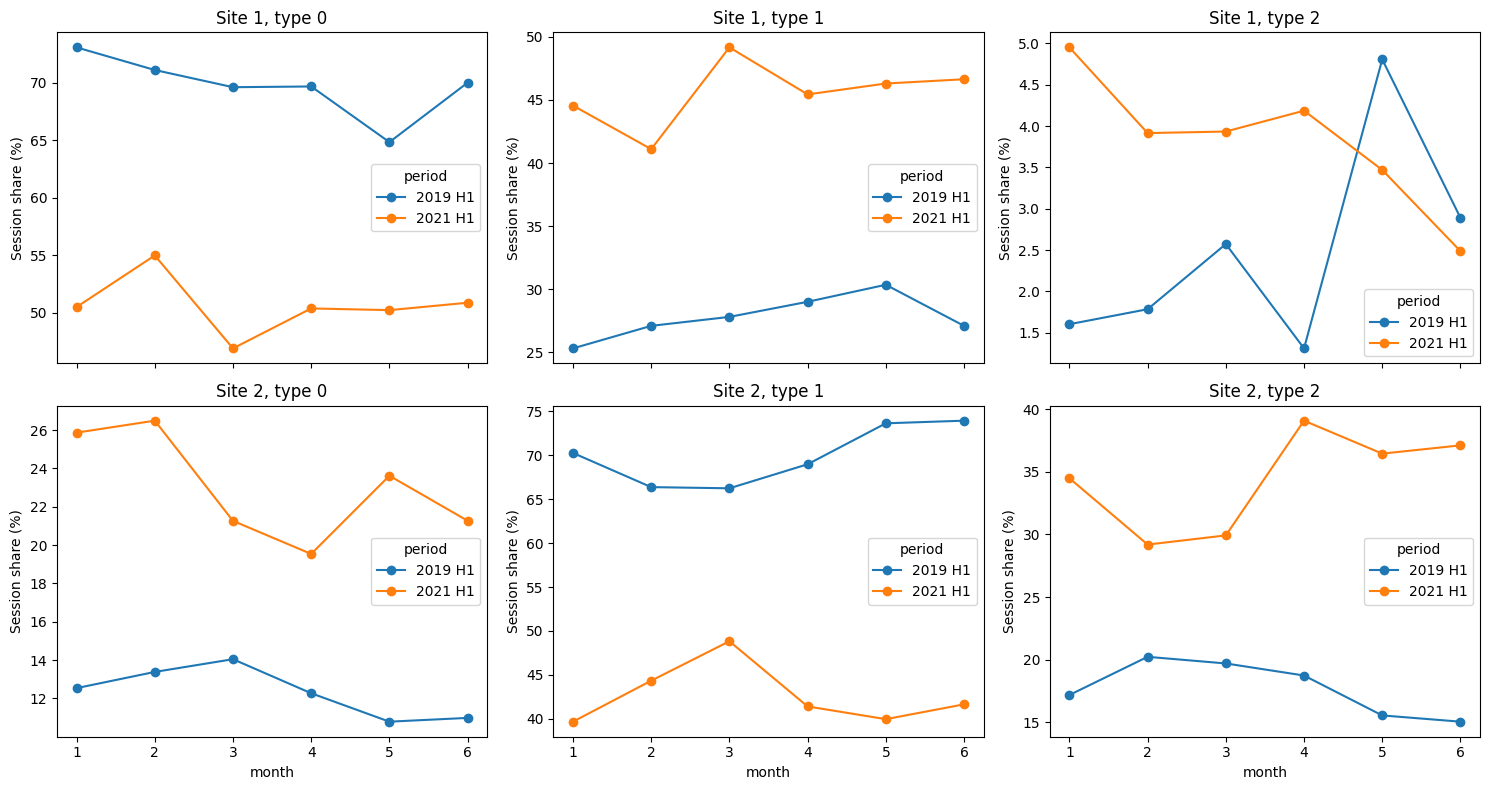

Matched identified site 1 users (at least five sessions in each half-year): 48


,2019 H1,2021 H1,change
energy,16.17,14.06,-2.10
duration,6.60,5.18,-1.42
frequency,8.42,5.33,-3.09


In [ ]:
# Long-term comparisons under the original site-specific session definitions.
periods = {
    "Reference": ("2018-09-01", "2019-07-01"),
    "2019 Q4": ("2019-10-01", "2020-01-01"),
    "2019 H1": ("2019-01-01", "2019-07-01"),
    "2021 H1": ("2021-01-01", "2021-07-01")
}
long_term_rows = []
overall_rows = []
monthly_rows = []
for site in [1, 2]:
    data = sessions.loc[sessions["siteID"].eq(site)
                        & sessions["connected_duration_hours"].gt(0)].copy()
    data["log_duration"] = np.log1p(data["connected_duration_hours"])
    data["log_energy"] = np.log1p(data["kWhDelivered"])
    fitted = site_models[site]
    data["session_group"] = fitted["model"].predict(fitted["scaler"].transform(data[session_features]))
    for period, (start, end) in periods.items():
        window = data.loc[data["date"].ge(start) & data["date"].lt(end)]
        profile = window.groupby("session_group").agg(
            sessions=("sessionID", "size"), median_energy_kWh=("kWhDelivered", "median"),
            median_connected_hours=("connected_duration_hours", "median")
        ).reindex(range(fitted["k"]))
        profile["sessions"] = profile["sessions"].fillna(0).astype(int)
        profile["share_pct"] = profile["sessions"] / len(window) * 100
        profile["site"], profile["period"] = site, period
        long_term_rows.append(profile.reset_index())
        overall_rows.append({"site": site, "period": period, "sessions": len(window),
            "recorded_months": window["date"].dt.to_period("M").nunique(),
            "mean_energy_kWh": window["kWhDelivered"].mean(),
            "median_energy_kWh": window["kWhDelivered"].median(),
            "mean_connected_hours": window["connected_duration_hours"].mean(),
            "median_connected_hours": window["connected_duration_hours"].median()})
        if period not in ["2019 H1", "2021 H1"]:
            continue
        window = window.assign(month=window["date"].dt.month)
        counts = pd.crosstab(window["month"], window["session_group"]).reindex(
            index=range(1, 7), columns=range(fitted["k"]), fill_value=0)
        shares = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0) * 100
        for month in shares.index:
            for group in shares.columns:
                monthly_rows.append({"site": site, "period": period, "month": month,
                    "session_group": group, "share_pct": shares.loc[month, group]})
long_term_profiles = pd.concat(long_term_rows, ignore_index=True)
long_term_overall = pd.DataFrame(overall_rows).set_index(["site", "period"])
monthly_type_shares = pd.DataFrame(monthly_rows)
# Equal month weights remove differing monthly volume weights within each half-year.
equal_month_shares = monthly_type_shares.groupby(["site", "session_group", "period"])["share_pct"].mean().unstack()
equal_month_shares["change_pp"] = equal_month_shares["2021 H1"] - equal_month_shares["2019 H1"]
display_table(long_term_profiles.set_index(["site", "period", "session_group"]).round(2))
display_table(long_term_overall.round(2))
display_table(equal_month_shares.round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for site in [1, 2]:
    for group in range(site_models[site]["k"]):
        subset = monthly_type_shares.loc[monthly_type_shares["site"].eq(site)
                                        & monthly_type_shares["session_group"].eq(group)]
        subset.pivot(index="month", columns="period", values="share_pct").plot(
            ax=axes[site-1, group], marker="o", title=f"Site {site}, type {group}")
        axes[site-1, group].set_ylabel("Session share (%)")
        axes[site-1, group].set_xticks(range(1, 7))
plt.tight_layout()
plt.show()

# Same identified site 1 users, eligible in both half-years.
past_users = user_profiles(users, pd.Timestamp("2019-01-01"), pd.Timestamp("2019-07-01"))
later_users = user_profiles(users, pd.Timestamp("2021-01-01"), pd.Timestamp("2021-07-01"))
matched_ids = past_users.index.intersection(later_users.index)
matched_periods = pd.DataFrame({
    "2019 H1": past_users.loc[matched_ids, ["energy", "duration", "frequency"]].mean(),
    "2021 H1": later_users.loc[matched_ids, ["energy", "duration", "frequency"]].mean()
})
matched_periods["change"] = matched_periods["2021 H1"] - matched_periods["2019 H1"]
print("Matched identified site 1 users (at least five sessions in each half-year):", len(matched_ids))
display_table(matched_periods.round(2))


### Findings — Two stages of observed change

**1. Before 2020, the sites followed different trajectories.** Between the reference period and 2019Q4, site 1 retained a similar session mix: the morning/long-connection share changed from 69.54% to 67.62%, while the afternoon/shorter-connection share changed from 28.04% to 29.20%. Within each type, median delivered energy increased while median connection duration remained approximately stable. At site 2, the morning-type share increased from 62.65% to 73.83% and the weekend share declined from 15.61% to 8.82%. Median energy and duration decreased in the morning type, whereas weekend medians were approximately unchanged. These are distributional comparisons, not evidence that the same sessions or users received more or less energy. The reference and test windows also differ in seasonal coverage.

**2. The same-calendar-half-year comparison shows substantial restructuring by 2021.** At site 1, the morning-type share fell from 69.56% in 2019H1 to 50.54% in 2021H1, while the afternoon-type share rose from 27.89% to 45.73%. At site 2, the morning-type share fell from 69.87% to 42.41%; evening-type and weekend shares rose from 17.78% to 35.12% and from 12.35% to 22.47%, respectively. Recorded sessions also fell from 8,610 to 3,864 at site 1 and from 5,759 to 1,700 at site 2. These counts measure observed use and cannot independently establish underlying demand or recording completeness.

**3. The compositional shift persists with equal weights for January–June.** The morning-type share decreases by 19.09 percentage points at site 1 and 27.29 points at site 2. Thus, the half-year result is not explained solely by assigning greater weight to high-volume months within each year. The figure compares matching months separately; the result remains descriptive because calendar matching does not remove all time-varying confounders.

**4. Shorter connection times do not imply unchanged energy demand at both sites.** Overall median connection duration fell from 8.53 to 5.36 hours at site 1 and from 6.09 to 1.25 hours at site 2. Site 1's median delivered energy remained close (11.26 versus 11.14 kWh), although its mean declined from 14.52 to 13.74 kWh. At site 2, both median and mean delivered energy increased, from 6.45 to 8.20 kWh and from 9.17 to 12.85 kWh. Therefore, the two sites exhibit shorter observed connections but different energy trajectories. Delivered energy is not a direct measurement of latent demand, and ratios of these aggregate summaries do not establish charging power or efficiency.

**5. Matched users provide a distinct, narrower perspective.** Among 48 identified site 1 users with at least five sessions in each half-year, the equally user-weighted mean session duration decreased from 6.60 to 5.18 hours and mean session energy from 16.17 to 14.06 kWh. Recorded monthly visit frequency decreased from 8.42 to 5.33. This supports a descriptive within-user change in the retained subset and shows why stable overall energy medians cannot be interpreted as unchanged individual requirements. The matched subset excludes many users and does not support conclusions about the anonymous site.

**6. Interpretation of the 2020 transition remains conditional.** Recorded activity drops sharply during 2020, and September–October 2020 contain no records at either site. The data support a shift away from the reference morning/long-connection pattern toward other recorded session patterns, but do not establish the cause or a precise break date. Reduced commuting is a plausible hypothesis, not a demonstrated mechanism. Operating schedules, access policies, charging control, equipment and data collection may also matter. These explanations require external operational evidence and a stronger identification design.

**Overall conclusion.** Short-term changes before 2020 and larger differences between 2019H1 and 2021H1 should be reported separately. The later comparison reveals both changing session composition and changing within-type characteristics. The compositional shift persists under matched-calendar-month and equal-month-weight comparisons, but energy outcomes differ by site and by analysis unit. The strongest supported claim is descriptive restructuring of observed charging behavior, not a universal reduction in energy needs or a causal effect of changed commuting.

**Figure interpretation.** Each panel compares a fixed reference type at one site across the same six calendar months. The two lines show monthly session shares, not user shares or absolute demand. Read these panels together with the collapsed period tables: compositional changes can coexist with lower total recorded volume and changes inside a type. Original reference labels remain fixed even when later within-type profiles differ.

**Count clarification.** Site 2 recorded 520 and 410 weekend-type sessions in September and October 2018. The corresponding 643 and 715 counts belong to the evening-type group, not the weekend group. Correct group identities must be retained in historical comparisons.

### RQ2 supplementary analysis — Identified site 1 users

Apply the same scaler and centroids in every quarter to keep labels comparable. Profiles require at least five sessions. Low-frequency users and anonymous sessions are therefore not represented. Missing whole months flag incomplete coverage; observed months may still contain partial gaps. No activity recorded does not establish user departure.

group,0,1
quarter,,
2018Q4,39,100
2019Q1,55,103
2019Q2,66,111
2019Q3,69,108
2019Q4,81,113
2020Q1,66,115
2020Q2,29,19
2020Q3,19,18
2020Q4,23,13


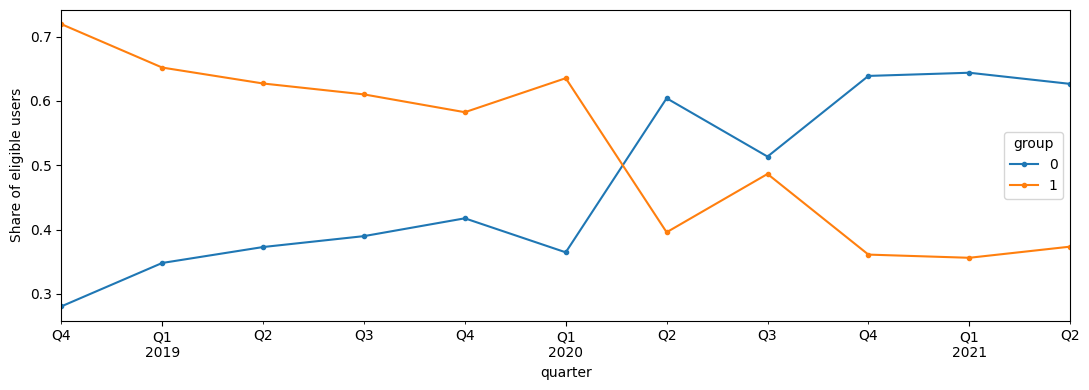

,eligible_users,mean_energy,mean_duration,mean_frequency,months_with_records
quarter,,,,,
2018Q4,139,14.796801,7.243472,7.207128,3
2019Q1,158,15.561712,7.043128,8.067436,3
2019Q2,177,15.768839,6.970129,8.042590,3
2019Q3,177,15.134495,6.816905,7.693487,3
2019Q4,194,15.700501,6.543565,6.910172,3
2020Q1,181,15.475693,6.666135,6.279317,3
2020Q2,48,16.524986,5.662754,5.288934,3
2020Q3,37,14.846600,6.024604,3.764450,2
2020Q4,36,14.427379,5.754702,4.098770,2


In [ ]:
quarter_profiles = []
for quarter in pd.period_range("2018Q4", "2021Q2", freq="Q"):
    profile = user_profiles(users, quarter.start_time, (quarter + 1).start_time)
    if not profile.empty:
        profile["group"] = cluster_model.predict(scaler.transform(profile[profile_features]))
        profile["quarter"] = quarter
        quarter_profiles.append(profile.reset_index())
quarter_profiles = pd.concat(quarter_profiles, ignore_index=True)
group_counts = pd.crosstab(quarter_profiles["quarter"], quarter_profiles["group"])
group_shares = group_counts.div(group_counts.sum(axis=1), axis=0)
display_table(group_counts)
group_shares.plot(figsize=(11, 4), marker=".", ylabel="Share of eligible users")
plt.tight_layout()
plt.show()

coverage = monthly_sessions[1].groupby(monthly_sessions.index.asfreq("Q")).count()
quarter_summary = quarter_profiles.groupby("quarter").agg(
    eligible_users=("userID", "nunique"), mean_energy=("energy", "mean"),
    mean_duration=("duration", "mean"), mean_frequency=("frequency", "mean")
)
quarter_summary["months_with_records"] = coverage
display_table(quarter_summary)

**Figure interpretation — eligible-user composition at site 1.** The lines show shares among users with at least five recorded sessions per quarter, not the full population. Eligible counts fall from 181 in 2020Q1 to 48 in 2020Q2, and the balance shifts toward the later-arrival/shorter-connection group. Such a shift may reflect changing eligibility and participation as well as individual behavior. Quarters with fewer than three recorded months are explicitly flagged; three recorded months do not guarantee complete daily coverage.

In [ ]:
# Adjacent-quarter changes among the same eligible users.
changes = []
transitions = {}
quarters = sorted(quarter_profiles["quarter"].unique())
for previous, current in zip(quarters[:-1], quarters[1:]):
    if current.ordinal - previous.ordinal != 1:
        continue
    before = quarter_profiles.loc[quarter_profiles["quarter"].eq(previous)].set_index("userID")
    after = quarter_profiles.loc[quarter_profiles["quarter"].eq(current)].set_index("userID")
    matched = before.index.intersection(after.index)
    if len(matched) == 0:
        continue
    transitions[str(current)] = pd.crosstab(
        before.loc[matched, "group"], after.loc[matched, "group"], normalize="index"
    )
    changes.append({
        "quarter": current, "matched_users": len(matched),
        "newly_eligible": len(after.index.difference(before.index)),
        "no_longer_eligible": len(before.index.difference(after.index)),
        "group_switch_share": before.loc[matched, "group"].ne(after.loc[matched, "group"]).mean(),
        "within_user_energy_change": (after.loc[matched, "energy"] - before.loc[matched, "energy"]).mean(),
        "within_user_duration_change": (after.loc[matched, "duration"] - before.loc[matched, "duration"]).mean(),
        "both_quarters_covered": coverage.get(previous, 0) == 3 and coverage.get(current, 0) == 3
    })
display_table(pd.DataFrame(changes).set_index("quarter"))

,matched_users,newly_eligible,no_longer_eligible,group_switch_share,within_user_energy_change,within_user_duration_change,both_quarters_covered
quarter,,,,,,,
2019Q1,116,42,23,0.120690,1.238245,0.046048,True
2019Q2,139,38,19,0.100719,-0.226723,-0.119239,True
2019Q3,146,31,31,0.075342,-0.129104,-0.195985,True
2019Q4,148,46,29,0.094595,0.633661,-0.182783,True
2020Q1,144,37,50,0.076389,-0.092214,0.170917,True
2020Q2,40,8,141,0.325000,-1.215728,-1.140494,True
2020Q3,24,13,24,0.208333,-0.416132,0.062744,False
2020Q4,21,15,16,0.285714,-0.093011,-0.391922,False
2021Q1,33,40,3,0.151515,0.111325,0.025677,False


**Matched-user finding.** During 2019, adjacent-quarter group-switch shares range from approximately 7.5% to 12.1%. In 2020Q2 the share reaches 32.5%, but only 40 users remain matched. For these users, mean session energy decreases by 1.22 kWh and mean connection duration by 1.14 hours. This is evidence of change in the observed matched subset, not a population-wide effect. Newly eligible and no-longer-eligible users are threshold categories, not confirmed entrants and departures.

### Change decomposition for reference users

Hold each reference user's group fixed. For represented groups, decompose the change in the user-weighted mean energy as

Δμ = Σₖ Δπₖ(μₖ,₁ + μₖ,₀)/2 + Σₖ Δμₖ(πₖ,₁ + πₖ,₀)/2.

The first term is between-group composition change; the second is within-group mean change. The latter can still reflect changing users inside a group, so the matched-user results above are needed separately. This is descriptive, not causal.

In [ ]:
fixed = quarter_profiles.join(reference["group"].rename("reference_group"), on="userID")
fixed = fixed.dropna(subset=["reference_group"])
decomposition = []
for previous, current in zip(quarters[:-1], quarters[1:]):
    if current.ordinal - previous.ordinal != 1:
        continue
    before = fixed.loc[fixed["quarter"].eq(previous)].groupby("reference_group")["energy"].agg(["size", "mean"])
    after = fixed.loc[fixed["quarter"].eq(current)].groupby("reference_group")["energy"].agg(["size", "mean"])
    if len(before) != best_k or len(after) != best_k:
        continue
    p0, p1 = before["size"] / before["size"].sum(), after["size"] / after["size"].sum()
    composition = ((p1 - p0) * (after["mean"] + before["mean"]) / 2).sum()
    within = ((after["mean"] - before["mean"]) * (p1 + p0) / 2).sum()
    total = (p1 * after["mean"]).sum() - (p0 * before["mean"]).sum()
    decomposition.append({"quarter": current, "composition_kWh": composition,
                          "within_group_kWh": within, "total_kWh": total,
                          "both_quarters_covered": coverage.get(previous, 0) == 3 and coverage.get(current, 0) == 3})
decomposition = pd.DataFrame(decomposition).set_index("quarter")
assert np.allclose(decomposition["composition_kWh"] + decomposition["within_group_kWh"], decomposition["total_kWh"])
display_table(decomposition)

,composition_kWh,within_group_kWh,total_kWh,both_quarters_covered
quarter,,,,
2019Q1,-0.233304,1.147571,0.914266,True
2019Q2,-0.004148,0.331618,0.327470,True
2019Q3,-0.034189,-0.083565,-0.117754,True
2019Q4,-0.128229,0.646226,0.517997,True
2020Q1,0.126951,-1.335614,-1.208664,True
2020Q2,0.586538,1.691932,2.278470,True
2020Q3,-0.459193,-1.436829,-1.896023,False
2020Q4,0.055298,-1.489297,-1.433998,False
2021Q1,-0.010296,0.265003,0.254707,False


**Decomposition finding.** For the eligible reference-user cohort, the 2020Q2 increase in user-weighted mean energy is 2.28 kWh: 0.59 from between-group composition and 1.69 from within-group mean changes. This can coexist with declining energy among matched users because the samples differ and within-group membership can change. The within-group term is not a pure individual behavioral effect. Periods with coverage gaps should not support strong trend claims.

## RQ3 — Cross-site pattern and predictive transfer

Predict delivered energy at connection using calendar features available at both sites. Exclude user IDs, departure time, final duration and user requests. Both sites share the same train/test dates and model settings. Compare local, source-only, pooled, and source plus one month of target data. Adaptation uses June 2019 only; compare with a target-June-only baseline. This tests predictive transfer, not identical user populations or causal site effects.

### RQ3a — Transfer of descriptive session patterns

Apply site 1's fixed reference model to later sessions at both sites, then repeat using site 2's model. Compare source-site and target-site test periods under the same source scaler and centroids. This avoids treating independently generated cluster numbers as equivalent.

Report cluster shares, nearest-centroid distance, and the fraction beyond the source reference distance's 95th percentile. Larger distances suggest weaker fit under that source representation, not a statistical proof of a novel behavior. The reference threshold is in-sample and descriptive. Compare distances within a source-model row only; scales differ between source models. Full-session outcomes are allowed here because this is retrospective pattern analysis, not arrival-time prediction.

Source model 1: cross-site total variation in test type shares = 0.335
Source model 2: cross-site total variation in test type shares = 0.078


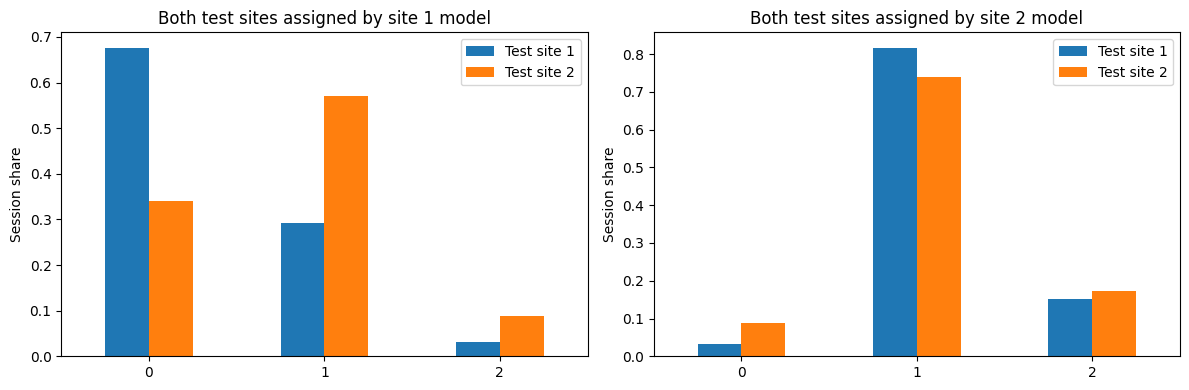

In [ ]:
pattern_transfer = []
pattern_shares = {}
for source in [1, 2]:
    fitted = site_models[source]
    reference_data = site_assignments[source]
    reference_values = fitted["scaler"].transform(reference_data[session_features])
    reference_distance = cdist(reference_values, fitted["model"].cluster_centers_).min(axis=1)
    threshold = np.quantile(reference_distance, 0.95)
    for target in [1, 2]:
        data = site_history[target]
        data = data.loc[data["date"].ge(stability_end) & data["date"].lt(test_end)]
        values = fitted["scaler"].transform(data[session_features])
        distances = cdist(values, fitted["model"].cluster_centers_)
        labels = distances.argmin(axis=1)
        nearest = distances.min(axis=1)
        shares = pd.Series(labels).value_counts(normalize=True).reindex(range(fitted["k"]), fill_value=0)
        pattern_shares[(source, target)] = shares
        pattern_transfer.append({"source_model": source, "test_site": target,
            "sessions": len(data), "mean_distance": nearest.mean(),
            "source_reference_p95": threshold, "beyond_reference_p95_share": (nearest > threshold).mean()})
pattern_transfer = pd.DataFrame(pattern_transfer).set_index(["source_model", "test_site"])
display_table(pattern_transfer.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, source in zip(axes, [1, 2]):
    shares = pd.DataFrame({f"Test site {target}": pattern_shares[(source, target)] for target in [1, 2]})
    shares.plot.bar(ax=ax, rot=0, ylabel="Session share", title=f"Both test sites assigned by site {source} model")
    distance = 0.5 * np.abs(shares.iloc[:, 0] - shares.iloc[:, 1]).sum()
    print(f"Source model {source}: cross-site total variation in test type shares = {distance:.3f}")
plt.tight_layout()
plt.show()

**Figure interpretation — directional pattern transfer.** Each panel applies one source model to both sites' test sessions, so the bars share a common labeling rule within that panel. Total variation between the two distributions is 0.335 under the site 1 model and 0.078 under the site 2 model. Using the site 1 model, 24.3% of site 2 test sessions exceed its reference distance threshold, compared with 6.1% at site 1. Using the site 2 model, the corresponding shares are 1.7% at site 1 and 3.9% at site 2.

The representation-dependent asymmetry suggests unequal descriptive coverage. It does not prove that the site 2 model is universally more transferable: scalers, partitions and thresholds differ. Distance exceedance is descriptive, not a significance test or proof of a new behavior type.

### RQ3b — Arrival-time predictive transfer

Retain the common-information energy prediction benchmark below. Actual energy, final connection duration and outcome-derived session labels are excluded from its inputs. Descriptive cluster transfer and predictive transfer answer different questions and are reported separately.

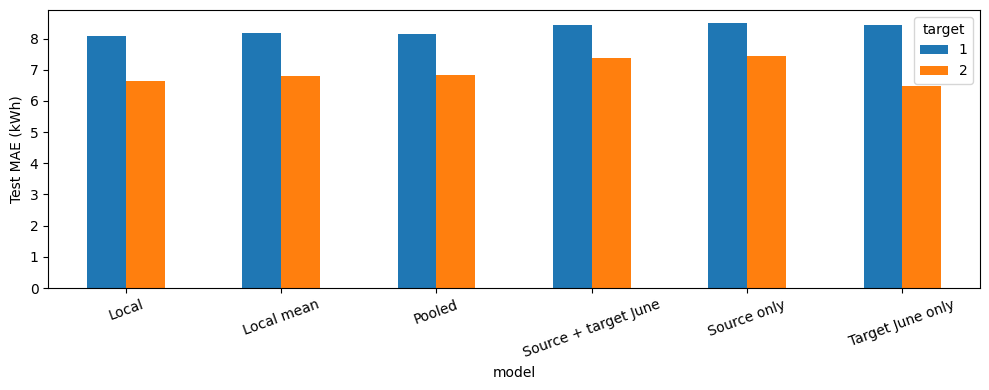

In [ ]:
prediction_features = ["arrival_sin", "arrival_cos", "weekend", "month_sin", "month_cos"]
train = sessions.loc[sessions["date"].ge(reference_start) & sessions["date"].lt(reference_end)]
test = sessions.loc[sessions["date"].ge(stability_end) & sessions["date"].lt(test_end)]
transfer_scores = []
transfer_errors = []
for target in [1, 2]:
    source = 3 - target
    target_test = test.loc[test["siteID"].eq(target)]
    target_train = train.loc[train["siteID"].eq(target)]
    source_train = train.loc[train["siteID"].eq(source)]
    adaptation = target_train.loc[target_train["date"].ge("2019-06-01")]
    training_sets = {
        "Local": target_train, "Source only": source_train, "Pooled": train,
        "Source + target June": pd.concat([source_train, adaptation]),
        "Target June only": adaptation
    }
    for name, training in training_sets.items():
        model = RandomForestRegressor(n_estimators=100, min_samples_leaf=20,
                                      random_state=42, n_jobs=-1)
        model.fit(training[prediction_features], training["kWhDelivered"])
        prediction = model.predict(target_test[prediction_features])
        error = np.abs(target_test["kWhDelivered"].to_numpy() - prediction)
        transfer_scores.append({"target": target, "model": name,
                                "train_sessions": len(training), "test_sessions": len(target_test),
                                "MAE_kWh": error.mean()})
        transfer_errors.append(pd.DataFrame({"target": target, "model": name,
            "day": target_test["date"].dt.normalize().to_numpy(), "error": error}))
    transfer_scores.append({"target": target, "model": "Local mean",
        "train_sessions": len(target_train), "test_sessions": len(target_test),
        "MAE_kWh": mean_absolute_error(target_test["kWhDelivered"],
                       np.repeat(target_train["kWhDelivered"].mean(), len(target_test)))})
transfer_scores = pd.DataFrame(transfer_scores)
display_table(transfer_scores.set_index(["target", "model"]))
transfer_scores.pivot(index="model", columns="target", values="MAE_kWh").plot.bar(
    figsize=(10, 4), ylabel="Test MAE (kWh)", rot=20
)
plt.tight_layout()
plt.show()

**Figure interpretation — predictive transfer errors.** Lower bars mean lower test MAE. Local models achieve 8.07 kWh at site 1 and 6.65 kWh at site 2; source-only models achieve 8.50 and 7.44 kWh. Direct transfer therefore increases MAE by approximately 5.2% and 11.8%. Pooled training does not outperform local training. At site 2, the June-only local baseline has the lowest observed MAE (6.48 kWh), a result requiring further temporal validation rather than a general claim that less data is better.

Local models improve only modestly over local mean baselines, indicating limited predictive information in the shared calendar features. Descriptive session labels use outcomes and are deliberately excluded from arrival-time predictors.

In [ ]:
# Paired day-bootstrap uncertainty for source-only minus local MAE.
# Conditions on fitted models; does not include training uncertainty.
transfer_errors = pd.concat(transfer_errors, ignore_index=True)
rng = np.random.default_rng(42)
for target in [1, 2]:
    daily = transfer_errors.loc[transfer_errors["target"].eq(target)].groupby(
        ["day", "model"]
    )["error"].agg(["sum", "size"])
    sums = daily["sum"].unstack()
    counts = daily["size"].unstack()["Local"]
    difference = (sums["Source only"] - sums["Local"]).to_numpy()
    indices = rng.integers(0, len(counts), size=(1000, len(counts)))
    draws = difference[indices].sum(axis=1) / counts.to_numpy()[indices].sum(axis=1)
    print("Target", target, "source minus local MAE:", difference.sum() / counts.sum(),
          "95% day-bootstrap interval:", np.quantile(draws, [0.025, 0.975]))

Target 1 source minus local MAE: 0.4133333086937294 95% day-bootstrap interval: [0.32509782 0.49193678]
Target 2 source minus local MAE: 0.7970459800442774 95% day-bootstrap interval: [0.65497896 0.95512328]


**Uncertainty finding.** Source-only minus local MAE is +0.422 kWh at site 1 (95% day-bootstrap interval: 0.337–0.501) and +0.784 kWh at site 2 (0.644–0.936). Both intervals remain above zero, supporting worse direct transfer in this test window conditional on the fitted models. The bootstrap does not capture training uncertainty, all cross-day dependence or performance in other time windows.

## Interpretation limits

- Group quality, future stability and predictive value are separate results; a high silhouette alone is insufficient.
- Group transitions may reflect sparse samples or clustering boundaries. Repeat with alternative K and minimum-session thresholds before making substantive claims.
- RQ2 estimates are conditional on eligible observed users. Missing records, access changes and user turnover cannot be fully separated without operational metadata.
- Site 2 is evaluated as anonymous sessions, regardless of partially populated ID fields.
- RQ3 uses a deliberately simple common-information benchmark. Pooled/adapted models also differ in training sample size; improvement alone does not isolate transferable structure.
- Delivered energy reflects both user demand and charging-system constraints. No causal or psychological interpretation is established by these analyses.


Main RQ2 results describe session populations at both sites. Supplementary user-level estimates apply only to eligible, identified site 1 users. Neither session-type shifts nor cross-site distances establish individual behavioral change or causal site effects.

## Answers to the research questions

### RQ1 — What distinct charging-session patterns can be identified at each site?

Both sites show three exploratory session types under the current feature set and K-selection rule. A weekday morning/long-connection pattern dominates both sites (69.5% at site 1; 62.6% at site 2). The shorter weekday pattern occurs mainly in the afternoon at site 1 and in the evening at site 2. Weekend sessions account for 2.4% and 15.6%, respectively. The sites share broad structure but differ in timing, duration and prevalence. These are session patterns, not verified user identities or psychological types; the strong weekend-feature influence requires sensitivity analysis.


### RQ2 — How do pattern prevalence and within-type characteristics change over time?

**Answer: Over the longer term, both sites become less dominated by the reference weekday morning/long-connection type. Overall connection durations decrease, but within-type duration and energy changes differ across types and sites.**

*Prevalence.*

- Before 2020, changes differ by site. Between the reference period and 2019Q4, site 1’s morning-type share remains relatively stable (69.54% → 67.62%), whereas site 2 becomes more concentrated in the morning type (62.65% → 73.83%) and its weekend share declines (15.61% → 8.82%).
- Between 2019H1 and 2021H1, the morning-type share decreases from **69.56% to 50.54% at site 1** and from **69.87% to 42.41% at site 2**. Site 1’s afternoon-type share increases from **27.89% to 45.73%**. At site 2, the evening-type share increases from **17.78% to 35.12%**, and the weekend share from **12.35% to 22.47%**. Equal-month weighting preserves the direction and approximate magnitude of these differences.

*Overall and within-type characteristics.*

- Overall median connection duration decreases from **8.53 to 5.36 hours at site 1** and from **6.09 to 1.25 hours at site 2**.
- Within-type changes are not uniform. At site 1, the morning type’s median duration decreases from **9.38 to 7.65 hours**, but the afternoon and weekend types increase from **3.03 to 3.76 hours** and **4.05 to 5.02 hours**, respectively. At site 2, median duration decreases in all three reference types.
- Overall median delivered energy remains similar at site 1 (**11.26 → 11.14 kWh**) but increases at site 2 (**6.45 → 8.20 kWh**). At site 2, this overall increase coexists with a slight decline within the morning type (**6.58 → 6.29 kWh**) and increases within the evening and weekend types.
- Among **48 matched site 1 users**, equally user-weighted mean session energy decreases from **16.17 to 14.06 kWh**, and mean connection duration from **6.60 to 5.18 hours**. Similar aggregate energy medians therefore do not establish unchanged individual behavior. The aggregate and matched-user analyses differ in population, weighting and summary statistic.

These findings indicate changes in both session composition and within-type characteristics. Type names refer to reference-period profiles; later sessions assigned to a “long-connection” type need not retain the original duration. The results are descriptive and do not identify reduced commuting or another causal mechanism.

### RQ3 — To what extent do patterns and prediction models transfer across sites?

**Answer: Descriptive matching is direction-dependent, while direct predictive transfer performs worse than local training in both directions under the current experimental setup.**

- *Descriptive patterns:* Under the site 2 model, **1.7%** of site 1 test sessions exceed the source reference distribution’s 95th-percentile nearest-centroid distance threshold. Under the site 1 model, **24.3%** of site 2 sessions exceed the corresponding threshold. Cross-site total variation in assigned type shares is **0.078** under the site 2 model and **0.335** under the site 1 model. This indicates asymmetric matching under the two representations. However, different scalers, partitions and thresholds prevent interpreting these results as proof that one model is universally more transferable.
- *Prediction:* Source-only models increase MAE by **5.2% at site 1** (**8.07 → 8.50 kWh**) and **11.8% at site 2** (**6.65 → 7.44 kWh**). The 95% day-bootstrap intervals for the MAE increases are **[0.337, 0.501] kWh** and **[0.644, 0.936] kWh**, respectively. Both exclude zero conditional on the fitted models. Pooling the two sites does not outperform local training.

Shared descriptive structure therefore does not guarantee predictive transfer under the current calendar-only features, model and test period. These findings do not rule out more effective adaptation methods.